# Gear spall prognostics from vibration indicators (PHM 2026 Data Challenge)

**Group 09 · SIADS 696** — estimate the severity of gear-tooth spall damage using only externally mounted vibration
sensors.

This notebook is the shareable, self-contained version of our work so far. It is organised in three parts:

| Part | What it covers | Source in the team repo |
|---|---|---|
| **1. Data extraction** | Where the data comes from, how the nested zip/HDF5 archives were flattened into per-second tables, what every table and label file contains | `scripts/phm_data.py`, `scripts/flatten_hdf5.py` |
| **2. Visualization (EDA)** | Run timelines, operating conditions, condition-indicator (CI) trajectories, indicator quality metrics, redundancy, oil debris, photo/condition labels | `eda/` |
| **3. Unsupervised learning** | Healthy-reference novelty detection: condition correction, Mahalanobis / PCA-SPE / Isolation-Forest health indices, leave-one-gear-out evaluation, label-free model selection, challenge submissions | `models/spall_hi.py`, `models/eval/` |

**How to run.** Unzip the archive and open this notebook from the unzipped folder (the `data/` directory must sit
next to it). Run the cells top to bottom; Part 3 depends on the tables loaded in Part 1. The whole notebook runs in
under a minute on a laptop (about 1.5 GB of RAM). Required packages: `pandas pyarrow numpy scipy scikit-learn matplotlib h5py pillow`
(see `requirements.txt`). On Colab: upload the zip, `!unzip -q spall_prognostics_team.zip`, then
`%cd spall_prognostics_team` before running the cells.

**What is in `data/`.**

```
data/channels.csv                      units and HDF5 provenance for every column of the parquet tables
data/<split>/lf_1s.parquet             one row per second: ids, timestamp, test_hours, 26 ci_* and 5 ctx_* columns
data/<split>/particles.parquet         one row per source file: DM4500 and ICM2 oil-debris particle counts (8 bins each)
data/<split>/manifest.csv              provenance of every extracted source file (zip, inner path, size)
data/validation|test/example_*.csv     the challenge submission templates
data/labels/condition_labels.csv       per-tooth condition score after every training run (1 healthy … 4 severe spalling)
data/labels/spall_scores.csv           earlier per-tooth spall scores for Exp-A and Exp-B only
data/train/lf_sample/*.hdf5            12 raw low-frequency HDF5 files (Exp-F Run-1) so the flattening step can be run here
data/train/photos_sample/*.jpg         4 tooth photos used as the damage rubric
data/eda/photo_proxy.csv               automated texture score per tooth photo (derived from the 1 GB photo set, not shipped)
```

Splits: **train** = gears A, B, C, F (run to failure, inspected after every run); **validation** = gear G;
**test** = gears D and E.

In [1]:
# Setup: imports, paths, shared plotting style
%pip install h5py pandas matplotlib pillow scikit-learn scipy --quiet

import json, re, warnings
from pathlib import Path

import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm, LinearSegmentedColormap, ListedColormap, Normalize
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle
from matplotlib.ticker import FuncFormatter, NullFormatter
from PIL import Image
from scipy.cluster.hierarchy import leaves_list, linkage
from scipy.ndimage import median_filter
from scipy.stats import spearmanr
from sklearn.covariance import LedoitWolf
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.isotonic import IsotonicRegression

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 160)

DATA = Path("data")
OUT = Path("out"); OUT.mkdir(exist_ok=True)
# assert (DATA / "train" / "lf.parquet").exists(), "Open this notebook from the unzipped folder: data/ must sit next to it"

SEED = 696
SPLITS = ["train", "validation", "test"]
TRAIN_GEARS = ["Exp-A", "Exp-B", "Exp-C", "Exp-F"]
ORDER_G = ["Exp-A", "Exp-B", "Exp-C", "Exp-F", "Exp-G", "Exp-D", "Exp-E"]

# palette (colour-vision-deficiency safe categorical slots, one-hue ordinal ramp)
BLUE, ORANGE, AQUA, GOLD = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
GEAR_C = dict(zip("ABCFGDE", [BLUE, ORANGE, AQUA, GOLD, "#8e5fd6", "#c8358a", "#52514e"]))
INK, INK2, MUTED, GRID, AXIS, SURFACE, THR, BASE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb", "#d03b3b", "#9a9993"
BLUES = LinearSegmentedColormap.from_list("blues", ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
GREYS = LinearSegmentedColormap.from_list("greys", ["#ffffff", "#f1f0ec", "#d9d7d0", "#a9a79f"])
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": AXIS, "axes.labelcolor": INK2,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "font.size": 10, "legend.frameon": False,
    "lines.linewidth": 1.6, "figure.dpi": 100,
})

def slog(v):
    """Signed log10(1 + |v|): keeps sign, compresses heavy tails."""
    v = np.asarray(v, dtype=float)
    return np.sign(v) * np.log10(1 + np.abs(v))

def break_gaps(x, y, gap=0.5):
    """Insert NaN where consecutive x jump more than `gap` hours so lines do not bridge missing runs."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    cut = np.where(np.diff(x) > gap)[0] + 1
    return np.insert(x, cut, np.nan), np.insert(y, cut, np.nan)

def plain_ticks(axis):
    """Label a log axis 0.1, 1, 10 instead of powers of ten."""
    axis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
    axis.set_minor_formatter(NullFormatter())

print("ready ·", DATA.resolve())


[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
ready · /Users/home/gkdev/siads696/Gear_Spall_Damage_Prognostics/data


---
# Part 1 · Data extraction

## 1.1 Where the data comes from

The PHM 2026 Data Challenge publishes three Synology shares (train, validation, test; the test share is
password-protected). Each share holds, per experiment (gear), zips **nested inside zips**: an outer
`Exp-X_HDF5_LF.zip` holds one `Exp-X_HDF5_Run-N_LF.zip` per run, which holds one HDF5 file per minute of dyno
logging. There are four modalities:

| Modality | Content | Size (all splits) | Shipped here |
|---|---|---|---|
| `lf` low-frequency | 1-s condition indicators + speed/torque/temperature + oil-debris counters | ~1.6 GB (29k files) | 12 sample files + the flattened parquet tables |
| `ci` | the CIs only (a subset of `lf`) | ~0.65 GB | no (redundant) |
| `hf` high-frequency | raw accelerometer waveforms, 4-s CIs | ~20 GB per split | no |
| `photos` | tooth photos taken between runs (train only) | ~1 GB (2,100 photos) | 4 rubric photos + a derived texture score |

`src/phm_data.py` (reference copy) talks to the Synology sharing API, downloads the small modalities, and un-nests
every archive into one flat folder per split with a `manifest.csv` that records the provenance of every file.
It needs network access and, for the test split, the challenge password, so it is **not** run here. The manifests
it produced are shipped and summarised below.

In [2]:
# 1.1 Manifests: what was extracted from the shares (files and MB per split, gear and modality)
man = pd.concat([pd.read_csv(DATA / s / "manifest.csv").assign(split=s) for s in SPLITS], ignore_index=True)
t = (man.groupby(["split", "experiment", "modality"])
        .agg(files=("file", "size"), MB=("size", lambda s: s.sum() / 1e6))
        .unstack("modality").round(0).fillna(0).astype(int))
t = t.reindex(pd.MultiIndex.from_tuples([(s, g) for s in SPLITS for g in ORDER_G if (s, g) in t.index]))
print(f"{len(man):,} extracted files · {man['size'].sum() / 1e9:.2f} GB in total")
t

50,340 extracted files · 8.77 GB in total


files                    MB                  
modality            ci  hf    lf photos   ci    hf   lf photos
train      Exp-A  1833   0  1833    455   47     0  125    215
           Exp-B  2375   0  2375    576   60     0  162    289
           Exp-C  4460   0  4460    788  113     0  300    414
           Exp-F  2910   0  2916    280   71     0  189    141
validation Exp-G  5889   0  5889      0  151     0  400      0
test       Exp-D  2162  66  2162      0   55  5480  146      0
           Exp-E  4455   0  4456      0  114     0  302      0

## 1.2 Inside one raw HDF5 file

Each low-frequency file is about one minute of logging. It has these groups:

- `CI/<metric>` — ~60 values, one per 1-s vibration window (FM4, NA4, M6A, RMS, kurtosis, …)
- `Context/<channel>` — ~60 values, one per second (speed, torque, temperature, accelerometer RMS)
- `DM4500 Data`, `ICM2 Data` — one oil-debris particle-count reading per file, in 8 size bins each

CI and Context are sampled on different clocks (offset by 0.5 s, often 59 vs 60 rows), so rows must be aligned on
timestamps derived from each dataset's `wf_start_time`, `wf_start_offset` and `wf_increment` attributes, never on
array position. The next cell lists every dataset in one sample file.

In [3]:
# 1.2 Walk one raw HDF5 file: groups, dataset shapes and the waveform-timing attributes
SAMPLE = sorted((DATA / "train" / "lf_sample").glob("*.hdf5"))
print(f"{len(SAMPLE)} sample files, e.g. {SAMPLE[0].name}\n")

def attr(ds, key, default=None):
    v = ds.attrs.get(key, default)
    return v.decode() if isinstance(v, bytes) else v

with h5py.File(SAMPLE[0]) as f:
    for group in f:
        print(f"{group}/")
        for name, ds in f[group].items():
            timing = {k: attr(ds, k) for k in ("wf_start_time", "wf_start_offset", "wf_increment") if k in ds.attrs}
            unit = attr(ds, "unit_string") or attr(ds, "NI_UnitDescription") or ""
            print(f"    {name:<22} shape={str(ds.shape):<7} {unit:<8} {timing}")

12 sample files, e.g. Exp-F_Run-1_LF_Dyno_Gear309Run1_00000.hdf5

CI/
    5-e_op                 shape=(60,)            {'wf_start_time': '2025-02-28T14:33:04.580845Z', 'wf_start_offset': 1.0, 'wf_increment': 1}
    6-e_op                 shape=(60,)            {'wf_start_time': '2025-02-28T14:33:04.580845Z', 'wf_start_offset': 1.0, 'wf_increment': 1}
    ALR                    shape=(60,)            {'wf_start_time': '2025-02-28T14:33:04.580845Z', 'wf_start_offset': 1.0, 'wf_increment': 1}
    FLEET_WTMADE           shape=(60,)            {'wf_start_time': '2025-02-28T14:33:04.580845Z', 'wf_start_offset': 1.0, 'wf_increment': 1}
    FM0                    shape=(60,)            {'wf_start_time': '2025-02-28T14:33:04.580845Z', 'wf_start_offset': 1.0, 'wf_increment': 1}
    FM4                    shape=(60,)            {'wf_start_time': '2025-02-28T14:33:04.580845Z', 'wf_start_offset': 1.0, 'wf_increment': 1}
    FM4star                shape=(60,)            {'wf_start_time': '2025-02-2

## 1.3 Flattening: HDF5 → one row per second

`src/flatten_hdf5.py` applies the function below to every `lf` file (8 worker processes, ~2 minutes per split) and
writes `lf_1s.parquet` and `particles.parquet` per split. Here we run the same code on the 12 shipped sample files
and check that the result matches the shipped table bit for bit.

In [4]:
# 1.3 The flattening step (same logic as src/flatten_hdf5.py), run on the sample files
PER_SECOND = {"CI": "ci", "Context": "ctx"}
PARTICLES = {"DM4500 Data": "dm4500", "ICM2 Data": "icm2"}

def col_name(prefix, name):
    return f"{prefix}_" + re.sub(r"[^0-9a-z]+", "_", name.lower()).strip("_")

def sample_times(ds):
    """Absolute timestamp of each sample; for windowed CIs, the start of each 1-s window."""
    t0 = pd.Timestamp(attr(ds, "wf_start_time")).tz_localize(None)
    inc = float(attr(ds, "wf_increment", 1.0))
    # CIs carry offset=1 (value stamped at the end of its window); shift back so row i = window [t0+i, t0+i+1)
    start = float(attr(ds, "wf_start_offset", 0.0)) - (inc if ds.parent.name.startswith("/CI") else 0.0)
    return t0 + pd.to_timedelta(start + inc * np.arange(ds.shape[0]), unit="s")

def read_file(path):
    m = re.match(r"(Exp-[A-Z])_(Run-\d+)_LF_Dyno_(Gear\d+Run\d+)_(\d+)(?:_chunk_(\d+))?", path.name)
    exp, run, session, seq, chunk = m.groups()
    ids = dict(experiment=exp, run=run, run_num=int(run.split("-")[1]), file=path.name,
               session=session, file_seq=int(seq), chunk=int(chunk or 0))
    series, particles = [], dict(ids)
    with h5py.File(path) as f:
        for group, prefix in PER_SECOND.items():
            for name, ds in f.get(group, {}).items():
                if ds.shape[0]:
                    series.append(pd.Series(ds[()], index=sample_times(ds), name=col_name(prefix, name)))
        for group, prefix in PARTICLES.items():
            for name, ds in f.get(group, {}).items():
                particles[col_name(prefix, name.split(" ", 1)[1])] = int(ds[0]) if ds.shape[0] else None
                particles.setdefault("timestamp", sample_times(ds)[0] if ds.shape[0] else pd.NaT)
    # align every channel on a 1-s grid anchored at the earliest window start in this file
    t0 = min(s.index[0] for s in series)
    for s in series:
        s.index = ((s.index - t0) / pd.Timedelta(seconds=1)).astype(int)
        if s.index.has_duplicates:
            s.drop(s.index[s.index.duplicated()], inplace=True)
    df = pd.concat(series, axis=1).sort_index()
    df.insert(0, "timestamp", t0 + pd.to_timedelta(df.index, unit="s"))
    df.insert(0, "second", df.index)
    for k, v in reversed(ids.items()):
        df.insert(0, k, v)
    return df.reset_index(drop=True), particles

frames, parts = zip(*[read_file(p) for p in SAMPLE])
lf_sample, pt_sample = pd.concat(frames, ignore_index=True), pd.DataFrame(parts)
print(f"{len(SAMPLE)} files -> {lf_sample.shape[0]} one-second rows x {lf_sample.shape[1]} columns; "
      f"{len(pt_sample)} particle readings")
lf_sample.head(3)

12 files -> 721 one-second rows x 40 columns; 12 particle readings


,experiment,run,run_num,file,session,file_seq,chunk,second,timestamp,ci_5_e_op,...,ci_rms,ci_rms_tsa,ci_rms_e_op,ci_skew_e_op,ci_v_peak_mmps,ctx_accel1_rms,ctx_accel2_rms,ctx_pau_speed,ctx_pau_torque,ctx_temperature
0,Exp-F,Run-1,1,Exp-F_Run-1_LF_Dyno_Gear309Run1_00000.hdf5,Gear309Run1,0,0,0,2025-02-28 14:33:04.580845,NaN,...,0.010249,NaN,NaN,NaN,0.002317,NaN,NaN,NaN,NaN,NaN
1,Exp-F,Run-1,1,Exp-F_Run-1_LF_Dyno_Gear309Run1_00000.hdf5,Gear309Run1,0,0,1,2025-02-28 14:33:05.580845,NaN,...,0.010239,NaN,NaN,NaN,0.002309,NaN,NaN,NaN,NaN,NaN
2,Exp-F,Run-1,1,Exp-F_Run-1_LF_Dyno_Gear309Run1_00000.hdf5,Gear309Run1,0,0,2,2025-02-28 14:33:06.580845,NaN,...,0.010217,NaN,NaN,NaN,0.002318,NaN,NaN,NaN,NaN,NaN


In [5]:
# 1.3 Check: the freshly flattened rows equal the shipped lf_1s.parquet rows for the same files
_filters = [("file", "in", [p.name for p in SAMPLE])]
shipped = pd.concat(
    [pd.read_parquet(DATA / "train" / "lf_part_1.parquet", filters=_filters),
     pd.read_parquet(DATA / "train" / "lf_part_2.parquet", filters=_filters)],
    ignore_index=True,
)
chk = lf_sample.merge(shipped, on=["file", "second"], suffixes=("", "_shipped"))
num = [c for c in lf_sample if c.startswith(("ci_", "ctx_"))]
max_abs_diff = max(np.nanmax(np.abs(chk[c] - chk[f"{c}_shipped"])) for c in num)
print(f"rows: rebuilt {len(lf_sample)}, shipped {len(shipped)}, matched {len(chk)}")
print(f"largest |difference| over {len(num)} numeric columns: {max_abs_diff:.3g}")
print("extra column in the shipped table:", sorted(set(shipped) - set(lf_sample)),
      "= cumulative hours with CI data within the experiment (added after sorting the whole split)")

rows: rebuilt 721, shipped 721, matched 721
largest |difference| over 31 numeric columns: 0
extra column in the shipped table: ['test_hours'] = cumulative hours with CI data within the experiment (added after sorting the whole split)


## 1.4 The flattened tables

`test_hours` is the cumulative number of seconds with CI data within an experiment, divided by 3600. It reproduces
the run-end times in the challenge submission templates to within a few minutes and is the time axis used
everywhere below.

In [6]:
# 1.4 Load the flattened tables for all three splits
LF = {
    s: pd.concat(
        [pd.read_parquet(DATA / "train" / "lf_part_1.parquet"),
         pd.read_parquet(DATA / "train" / "lf_part_2.parquet")],
        ignore_index=True,
    )
    for s in SPLITS
}
PT = {s: pd.read_parquet(DATA / s / "particles.parquet") for s in SPLITS}
channels = pd.read_csv(DATA / "channels.csv")

rows = []
for s in SPLITS:
    x = LF[s]
    for g, xg in x.groupby("experiment"):
        rows.append(dict(split=s, gear=g, runs=xg.run_num.nunique(), files=xg.file.nunique(), seconds=len(xg),
                         hours=round(xg.test_hours.max(), 1), first=xg.timestamp.min().date(), last=xg.timestamp.max().date()))
pd.DataFrame(rows).set_index(["split", "gear"])

runs  files  seconds  hours       first        last
split      gear                                                      
train      Exp-A     5   1833   110205   30.5  2024-09-16  2024-09-24
           Exp-B     7   2375   142082   39.4  2024-10-04  2024-10-24
           Exp-C    12   4460   267021   73.9  2024-10-31  2024-11-15
           Exp-F     8   2910   158527   43.8  2025-02-28  2025-03-18
validation Exp-A     5   1833   110205   30.5  2024-09-16  2024-09-24
           Exp-B     7   2375   142082   39.4  2024-10-04  2024-10-24
           Exp-C    12   4460   267021   73.9  2024-10-31  2024-11-15
           Exp-F     8   2910   158527   43.8  2025-02-28  2025-03-18
test       Exp-A     5   1833   110205   30.5  2024-09-16  2024-09-24
           Exp-B     7   2375   142082   39.4  2024-10-04  2024-10-24
           Exp-C    12   4460   267021   73.9  2024-10-31  2024-11-15
           Exp-F     8   2910   158527   43.8  2025-02-28  2025-03-18

In [7]:
# 1.4 Column dictionary: every ci_* / ctx_* / particle column with its HDF5 source and unit
# 1.4 Column dictionary: every ci_* / ctx_* / particle column with its HDF5 source and unit
# Ensure the split tables exist in the format used elsewhere in the notebook.
if isinstance(LF, pd.DataFrame):
      LF = {"train": LF}
for s in SPLITS:
      if s not in LF:
            lf_path = DATA / s / "lf_part_1.parquet"
            lf_path2 = DATA / s / "lf_part_2.parquet"
            if lf_path.exists():
                  df = pd.read_parquet(lf_path)
                  if lf_path2.exists():
                        df = pd.concat([df, pd.read_parquet(lf_path2)], ignore_index=True)
                  LF[s] = df
            elif (DATA / s / "lf.parquet").exists():
                  LF[s] = pd.read_parquet(DATA / s / "lf.parquet")
            else:
                  LF[s] = pd.DataFrame()

if "PT" not in globals():
      PT = {}
for s in SPLITS:
      p = DATA / s / "particles.parquet"
      PT[s] = pd.read_parquet(p) if p.exists() else pd.DataFrame()

if "channels" not in globals():
      channels = pd.read_csv(DATA / "channels.csv")

CI_ALL = [c for c in LF["train"] if c.startswith("ci_")]
CTX = [c for c in LF["train"] if c.startswith("ctx_")]
print(f"{len(CI_ALL)} condition indicators, {len(CTX)} context channels, "
        f"{PT['train'].filter(like='bin').shape[1] or 16} particle bins (in particles.parquet)")
channels[["column", "hdf5_path", "unit"]].fillna("").set_index("column")
CTX = [c for c in LF["train"] if c.startswith("ctx_")]
print(f"{len(CI_ALL)} condition indicators, {len(CTX)} context channels, "
      f"{LF['train'].filter(like='bin').shape[1] or 16} particle bins (in particles.parquet)")
channels[["column", "hdf5_path", "unit"]].fillna("").set_index("column")

26 condition indicators, 5 context channels, 16 particle bins (in particles.parquet)
26 condition indicators, 5 context channels, 16 particle bins (in particles.parquet)


,hdf5_path,unit
column,,
ci_5_e_op,CI/5-e_op,
ci_6_e_op,CI/6-e_op,
ci_alr,CI/ALR,
ci_fleet_wtmade,CI/FLEET_WTMADE,
ci_fm0,CI/FM0,
ci_fm4,CI/FM4,
ci_fm4star,CI/FM4star,
ci_m6a,CI/M6A,
ci_m6astar,CI/M6Astar,


## 1.5 Labels

After every training run the rig was stopped and all 28 teeth of the gear were inspected. `condition_labels.csv`
gives one **condition score per tooth per run end**: 1 = healthy, 2 = spall onset, 3 = spalling, 4 = severe
spalling (fractional values are interpolated grades). Exp-C is scored on teeth 1–14 only. We summarise a run end by
the **mean over teeth of (score − 1)**, which we call `mean_ex` (0 = all healthy, 3 = everything severely spalled),
and by the worst tooth `max`. A run end is a *spall event* when any tooth has reached 2.

`spall_scores.csv` is an earlier label set covering Exp-A and Exp-B only. The labels are used **only to evaluate**
models in Part 3, never to fit them.

In [8]:
# 1.5 Condition labels: per-tooth scores and run-level targets
LAB = pd.read_csv(DATA / "labels" / "condition_labels.csv")
lab_runs = (LAB.groupby(["experiment", "run_num"]).score
              .agg(mean_ex=lambda s: (s - 1).mean(), max="max", n_teeth="size").reset_index())
ONSET_RUN = lab_runs[lab_runs["max"] >= 2].groupby("experiment").run_num.min()   # first run end with a spall
print("labelled run ends per gear:", lab_runs.groupby("experiment").size().to_dict())
print("first run with a tooth at spall onset (score >= 2):", ONSET_RUN.to_dict())

pivot = LAB[LAB.experiment == "Exp-F"].pivot(index="tooth", columns="run_num", values="score")
pivot.columns = [f"after run {c}" for c in pivot.columns]
print("\nExp-F tooth x run-end condition scores (1 healthy ... 4 severe spalling):")
pivot.T.round(1)

labelled run ends per gear: {'Exp-A': 5, 'Exp-B': 7, 'Exp-C': 12, 'Exp-F': 8}
first run with a tooth at spall onset (score >= 2): {'Exp-A': 5, 'Exp-B': 4, 'Exp-C': 12, 'Exp-F': 3}

Exp-F tooth x run-end condition scores (1 healthy ... 4 severe spalling):


tooth,1,2,3,4,5,6,7,8,9,10,...,19,20,21,22,23,24,25,26,27,28
after run 1,1.2,1.0,1.0,1.3,1.4,1.3,1.3,1.3,1.0,1.0,...,1.1,1.0,1.1,1.1,1.0,1.0,1.0,1.5,1.0,1.5
after run 2,1.6,1.5,1.5,1.4,1.5,1.5,1.4,1.4,1.1,1.1,...,1.2,1.2,1.3,1.2,1.0,1.2,1.2,1.4,1.0,1.3
after run 3,1.5,1.4,1.4,1.5,2.0,1.3,1.4,1.4,1.2,1.3,...,1.4,1.4,1.3,1.2,1.1,1.2,1.1,1.4,1.2,1.5
after run 4,1.5,1.4,1.4,1.0,1.0,1.0,1.6,1.6,1.4,1.4,...,1.4,1.3,1.5,1.5,1.3,1.4,1.4,1.6,1.5,1.7
after run 5,1.6,2.0,1.5,2.0,1.6,1.4,1.4,1.3,1.2,1.3,...,2.0,1.5,1.7,2.0,2.0,2.0,2.0,1.5,1.4,1.4
after run 6,1.5,2.0,2.0,2.0,1.8,1.5,1.4,1.5,2.0,1.4,...,2.0,1.4,2.0,2.0,2.0,2.0,2.0,1.7,2.0,1.6
after run 7,1.5,2.0,2.0,2.0,1.6,1.5,1.4,1.5,3.0,2.0,...,2.0,1.7,2.0,1.6,2.0,2.0,2.0,2.0,2.0,1.4
after run 8,1.4,2.0,2.0,2.0,1.5,1.7,1.4,1.4,3.0,1.8,...,2.0,3.0,2.0,2.0,2.0,2.0,1.8,2.0,2.0,1.7


---
# Part 2 · Visualization (EDA)

## 2.1 Analysis tables

Three cleaning steps are applied before any analysis:

1. **Duplicate run.** The Exp-A Run-2 files are byte copies of Run-1 at the source. We blank their values but keep
   the nominal hour axis so run ends still line up with the inspections.
2. **Steady state.** A second counts as steady when speed is within 20 rpm of 1,400 rpm and torque within 5 % of
   the gear's median torque. Everything else (start-up, coast-down, load changes) is excluded.
3. **One-minute medians.** Steady seconds are reduced to one median per minute per run. This is the table the
   models in Part 3 are fit on.

In [9]:
# 2.1 Build S1 (all seconds, flagged), M1 (steady 1-minute medians) and PART (particle readings)
frames, parts = [], []
for s in SPLITS:
    x = LF[s].copy(); x["split"] = s
    dup = (x.experiment == "Exp-A") & (x.run_num == 2)
    x.loc[dup, CI_ALL + CTX] = np.nan
    x["minute"] = (x.test_hours * 60).astype(int)
    frames.append(x)
    p = PT[s].copy(); p["split"] = s
    parts.append(p[~((p.experiment == "Exp-A") & (p.run_num == 2))])
S1 = pd.concat(frames, ignore_index=True)
PART = pd.concat(parts, ignore_index=True)

nom_t = S1.groupby("experiment").ctx_pau_torque.transform("median")
S1["steady"] = (S1.ctx_pau_speed.sub(1400).abs() < 20) & (S1.ctx_pau_torque.sub(nom_t).abs() < 0.05 * nom_t)
M1 = S1[S1.steady].groupby(["split", "experiment", "run_num", "minute"])[CI_ALL + CTX].median().reset_index()
M1["hours"] = M1.minute / 60

runs = S1.groupby(["experiment", "run_num"]).agg(h0=("test_hours", "min"), h1=("test_hours", "max"),
                                                 temp=("ctx_temperature", "median")).reset_index()
runs["dup"] = (runs.experiment == "Exp-A") & (runs.run_num == 2)
runs["short"] = (runs.h1 - runs.h0) < 3
H1 = runs.set_index(["experiment", "run_num"]).h1
ONSET_H = {g: float(H1[(g, r)]) for g, r in ONSET_RUN.items()}        # hours at the first spall-event run end
print(f"{len(S1):,} one-second rows · {S1.steady.mean():.1%} steady · {len(M1):,} steady minutes · {len(PART):,} particle readings")
print("steady share per gear:", S1.groupby("experiment").steady.mean().round(3).to_dict())

2,033,505 one-second rows · 93.8% steady · 31,758 steady minutes · 23,158 particle readings
steady share per gear: {'Exp-A': 0.77, 'Exp-B': 0.971, 'Exp-C': 0.972, 'Exp-F': 0.966}


In [10]:
# 2.2 One row per gear
rows = []
for g in ORDER_G:
    x, r = S1[S1.experiment == g], runs[runs.experiment == g]
    rows.append(dict(gear=g, split=x.split.iloc[0], runs=r.run_num.nunique(), end_h=r.h1.max(),
                     sensor_h=x.ci_fm4.notna().sum() / 3600, steady_pct=100 * x.steady.mean(),
                     torque_ftlbf=x.ctx_pau_torque.median(), oil_temp_F=x.ctx_temperature.median(),
                     files=x.file.nunique(), rows=len(x), short_runs=int(r.short.sum()),
                     first_spall_h=ONSET_H.get(g, np.nan)))
gear_table = pd.DataFrame(rows).set_index("gear")
gear_table.round({"end_h": 1, "sensor_h": 1, "steady_pct": 0, "torque_ftlbf": 0, "oil_temp_F": 0, "first_spall_h": 1})

IndexError: single positional indexer is out-of-bounds

## 2.3 Run timeline

Every gear was run in blocks of about 6 hours. Training gears were inspected after every run; the bar colour shows
the worst tooth score at that inspection and the number inside is the mean tooth damage `mean_ex`. Gear A ran at
120 ft·lbf, the others at 100.

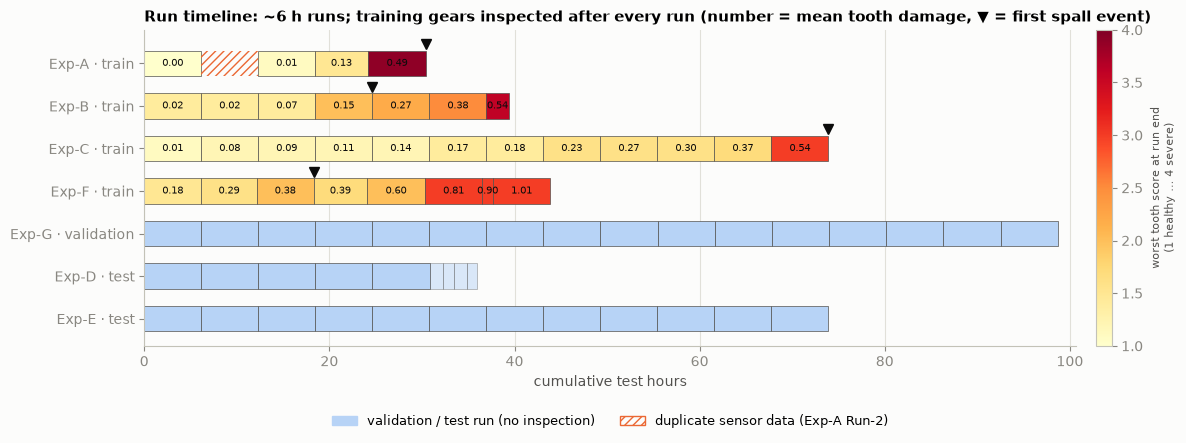

In [ ]:
# 2.3 Run timeline for all seven gears; training-gear runs coloured by the worst tooth score at the run end
norm, cmap = Normalize(1, 4), plt.get_cmap("YlOrRd")
t = runs.merge(lab_runs, on=["experiment", "run_num"], how="left")
fig, ax = plt.subplots(figsize=(12, 4.6))
for i, g in enumerate(ORDER_G):
    y = len(ORDER_G) - 1 - i
    for r in t[t.experiment == g].itertuples():
        if r.dup:
            kw = dict(facecolor="none", edgecolor=ORANGE, hatch="////", lw=0)
        elif pd.notna(r.max):
            kw = dict(color=cmap(norm(r.max)), edgecolor=INK2, lw=0.5)
        else:
            kw = dict(color="#b7d3f6", edgecolor=INK2, lw=0.5, alpha=0.5 if r.short else 1)
        ax.barh(y, r.h1 - r.h0, left=r.h0, height=0.6, **kw)
        if pd.notna(r.mean_ex) and not r.dup:
            ax.text((r.h0 + r.h1) / 2, y, f"{r.mean_ex:.2f}", ha="center", va="center", fontsize=7, color=INK)
    if g in ONSET_H:
        ax.plot(ONSET_H[g], y + 0.45, marker="v", ms=7, color=INK, clip_on=False)
ax.set_yticks(range(len(ORDER_G)), [f"{g} · {gear_table.loc[g, 'split']}" for g in ORDER_G[::-1]])
ax.set_xlim(0, runs.h1.max() * 1.02); ax.set_xlabel("cumulative test hours"); ax.grid(axis="y", visible=False)
ax.set_title("Run timeline: ~6 h runs; training gears inspected after every run (number = mean tooth damage, ▼ = first spall event)")
cb = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax, fraction=0.03, pad=0.02)
cb.set_label("worst tooth score at run end\n(1 healthy … 4 severe)", fontsize=8)
ax.legend(handles=[Patch(color="#b7d3f6", label="validation / test run (no inspection)"),
                   Patch(facecolor="none", edgecolor=ORANGE, hatch="////", label="duplicate sensor data (Exp-A Run-2)")],
          loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2, fontsize=9)
plt.tight_layout(); plt.show()

## 2.4 Operating conditions

Speed is held at 1,400 rpm; torque is nominally constant per gear; oil temperature drifts by tens of °F within a
run and between runs. Temperature and torque both move the vibration indicators, which is why Part 3 regresses them
out before scoring.

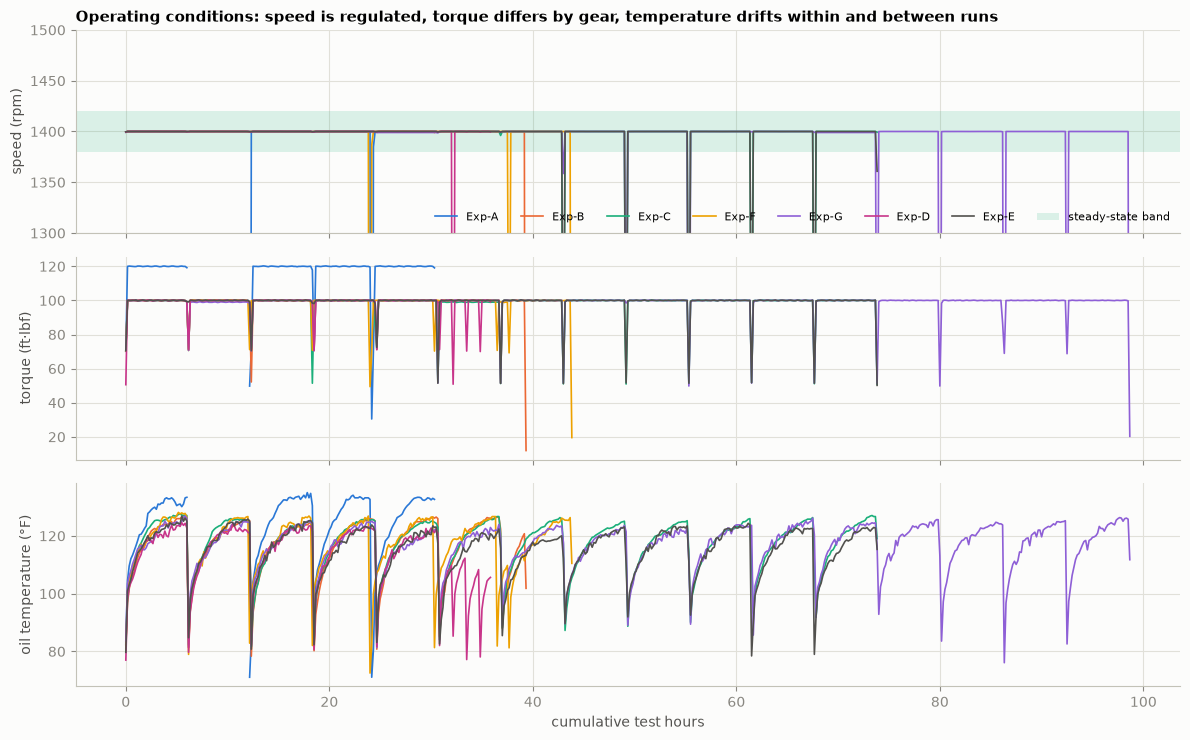

In [ ]:
# 2.4 Speed, torque and oil temperature per gear (10-minute medians of all seconds, not only steady ones)
ctx10 = S1.assign(h10=(S1.test_hours * 6).astype(int)).groupby(["experiment", "h10"])[CTX].median().reset_index()
ctx10["hours"] = ctx10.h10 / 6
fig, axes = plt.subplots(3, 1, figsize=(12, 7.5), sharex=True)
for ax, (col, label) in zip(axes, [("ctx_pau_speed", "speed (rpm)"), ("ctx_pau_torque", "torque (ft·lbf)"),
                                   ("ctx_temperature", "oil temperature (°F)")]):
    for g in ORDER_G:
        d = ctx10[ctx10.experiment == g]
        x, y = break_gaps(d.hours, d[col])
        ax.plot(x, y, color=GEAR_C[g[-1]], lw=1.2, label=g)
    ax.set_ylabel(label)
axes[0].axhspan(1380, 1420, color=AQUA, alpha=0.15, lw=0, label="steady-state band")
axes[0].set_ylim(1300, 1500); axes[0].legend(ncol=8, fontsize=8, loc="lower right")
axes[0].set_title("Operating conditions: speed is regulated, torque differs by gear, temperature drifts within and between runs")
axes[-1].set_xlabel("cumulative test hours")
plt.tight_layout(); plt.show()

## 2.5 Condition-indicator trajectories

To compare gears with different healthy signatures, each CI is expressed as a **robust z-score against the gear's own
first 12 hours**: (x − median) / (1.4826 · MAD) of the baseline window. The y-axis is a signed log so the ±1,000σ
excursions of the global indicators and the ±5σ movements of the tooth indicators fit on one scale.

Two indicators are plotted: **FM4** (a kurtosis of the residual signal, designed to respond to localised tooth damage)
and **TSA RMS** (an energy indicator). Change `plot_ci("ci_...")` to look at any other column.

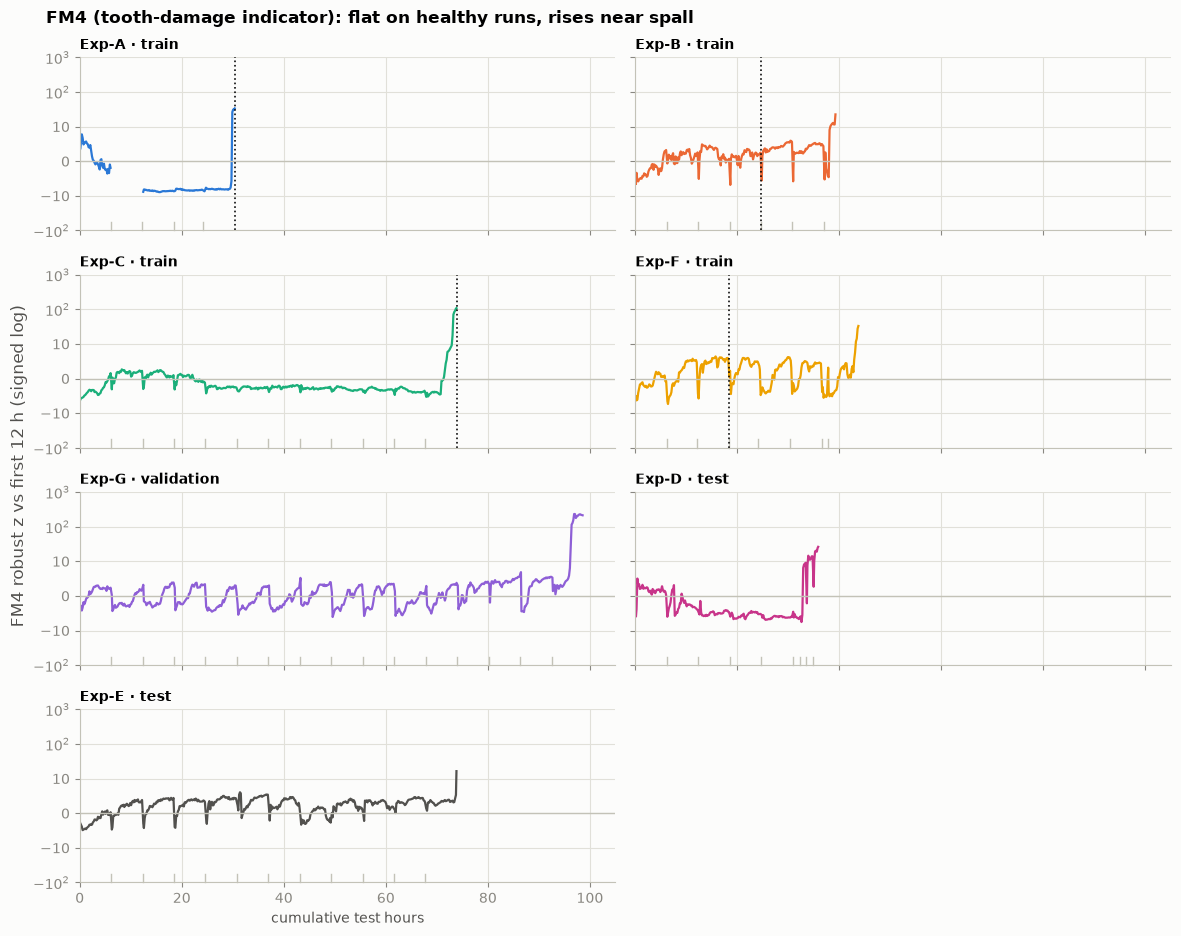

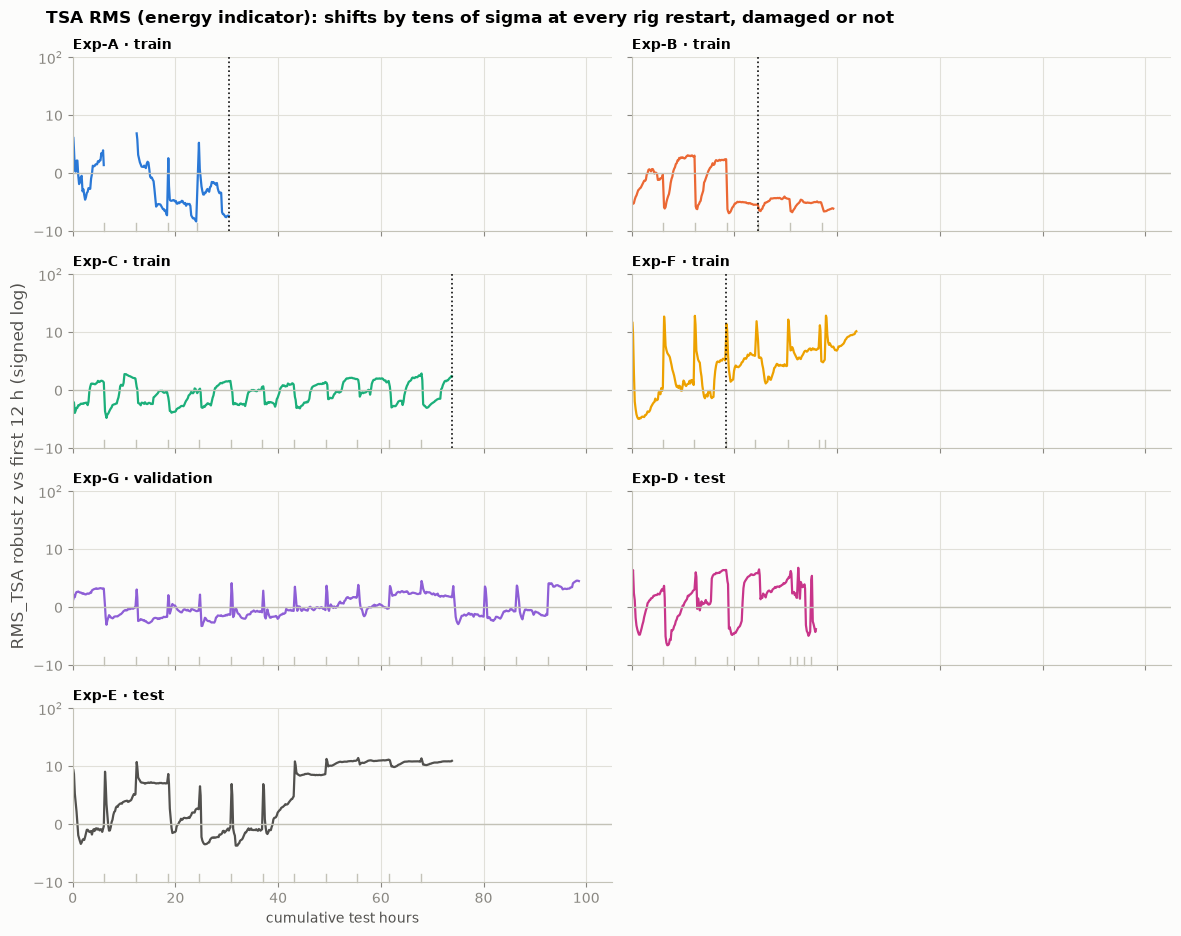

In [ ]:
# 2.5 Robust z per gear against its own 0.5-12 h baseline, then small multiples of one CI across the seven gears
BASE_EDA = (0.5, 12.0)
Zs = {}
for g in ORDER_G:
    x = M1[M1.experiment == g].sort_values("hours")
    b = x[(x.hours > BASE_EDA[0]) & (x.hours < BASE_EDA[1])]
    med = b[CI_ALL].median()
    mad = (b[CI_ALL] - med).abs().median() * 1.4826
    z = (x[CI_ALL] - med) / mad.replace(0, np.nan)
    z["hours"], z["run_num"], z["temp"] = x.hours.values, x.run_num.values, x.ctx_temperature.values
    Zs[g] = z

def run_ticks(ax, g):
    tr = ax.get_xaxis_transform()
    for h0 in runs[(runs.experiment == g) & (runs.run_num > 1)].h0:
        ax.plot([h0, h0], [0, 0.05], color=AXIS, lw=1, transform=tr, clip_on=False)

def plot_ci(ci, title=None):
    fig, axes = plt.subplots(4, 2, figsize=(12, 9.5), sharex=True, sharey=True)
    for ax, g in zip(axes.flat, ORDER_G):
        z = Zs[g]; a = z.groupby((z.hours * 6).astype(int)).median()      # 10-minute medians
        x, y = break_gaps(a.hours, slog(a[ci]))
        ax.plot(x, y, color=GEAR_C[g[-1]])
        ax.axhline(0, color=AXIS, lw=1); run_ticks(ax, g)
        if g in ONSET_H:
            ax.axvline(ONSET_H[g], color=INK, lw=1.2, ls=":")
        ax.set_title(f"{g} · {gear_table.loc[g, 'split']}", fontsize=10)
    axes.flat[-1].axis("off")
    ax0 = axes.flat[0]; ax0.set_xlim(0, 105)
    lo, hi = ax0.get_ylim(); ticks = np.arange(np.floor(lo), np.ceil(hi) + 1)
    ax0.set_yticks(ticks, [("−" if t < 0 else "") + ("0" if t == 0 else "10" if abs(t) == 1 else f"10$^{{{int(abs(t))}}}$") for t in ticks])
    for ax in axes[-1]: ax.set_xlabel("cumulative test hours")
    fig.supylabel(f"{ci[3:].upper()} robust z vs first 12 h (signed log)", color=INK2)
    fig.suptitle(title or f"{ci[3:].upper()} per gear · ticks = run boundaries · dotted = first spall event (labels)",
                 x=0.05, ha="left", fontweight="bold")
    plt.tight_layout(); plt.show()

plot_ci("ci_fm4", "FM4 (tooth-damage indicator): flat on healthy runs, rises near spall")
plot_ci("ci_rms_tsa", "TSA RMS (energy indicator): shifts by tens of sigma at every rig restart, damaged or not")

## 2.6 Indicator quality

Prognostic-parameter metrics after Coble & Hines (2009), computed on the robust-z trajectories of all seven gears:

- **Trendability** — mean pairwise correlation of the gears' trajectories on a common 0–1 life axis.
- **Monotonicity** — |#rises − #falls| / (n − 1) of the smoothed half-hourly trajectory.
- **Prognosability** — exp(−std(end values) / mean |end value|): do gears end at a similar level?
- **Temp |ρ|** — Spearman correlation with oil temperature in the baseline window (a confounder).
- **Gear offset** — spread of the gears' baseline medians in units of the within-gear SD (how different the
  healthy signatures are).

In [ ]:
# 2.6 Coble & Hines indicator metrics on all seven gears
def mono(v):
    d = np.sign(np.diff(v)); d = d[d != 0]
    return abs(d.sum()) / max(len(v) - 1, 1)

stats = []
for c in CI_ALL:
    mons, traj, ends, rhos, bmeds, bsds = [], [], [], [], [], []
    for g in ORDER_G:
        zz = Zs[g][[c, "hours"]].dropna()
        mons.append(mono(zz.groupby((zz.hours * 2).astype(int))[c].median().rolling(4, min_periods=1).median().values))
        traj.append(np.interp(np.linspace(0.05, 1, 40), (zz.hours / zz.hours.max()).values,
                              zz[c].rolling(60, min_periods=10).median().bfill().values))
        ends.append(zz[zz.hours > zz.hours.max() - 1][c].median())
        x = M1[M1.experiment == g]; b = x[(x.hours > BASE_EDA[0]) & (x.hours < BASE_EDA[1])]
        rhos.append(abs(spearmanr(b[c], b.ctx_temperature, nan_policy="omit")[0]))
        bmeds.append(b[c].median()); bsds.append(b[c].std())
    cc = np.corrcoef(np.array(traj)); ends = np.array(ends)
    stats.append(dict(indicator=c[3:].upper(), trendability=np.nanmean(cc[np.triu_indices(len(traj), 1)]),
                      monotonicity=np.mean(mons), prognosability=np.exp(-np.nanstd(ends) / np.nanmean(np.abs(ends))),
                      end_z_median=np.nanmedian(ends), temp_rho=np.nanmedian(rhos), gear_offset_sd=np.std(bmeds) / np.mean(bsds)))
quality = pd.DataFrame(stats).sort_values("trendability", ascending=False).set_index("indicator")
quality.round(2)

,trendability,monotonicity,prognosability,end_z_median,temp_rho,gear_offset_sd
indicator,,,,,,
M8A,0.66,0.20,0.13,40.46,0.51,2.84
M6A,0.64,0.22,0.18,27.35,0.53,3.37
FM4,0.57,0.22,0.25,18.55,0.50,3.81
FLEET_WTMADE,0.47,0.20,0.48,7.56,0.28,5.23
M8ASTAR,0.44,0.13,0.09,85.82,0.26,5.74
M6ASTAR,0.38,0.13,0.09,37.15,0.25,7.00
ALR,0.31,0.25,0.28,4.81,0.37,6.16
FM4STAR,0.28,0.14,0.10,14.73,0.21,8.77
KURTOSIS_TSA,0.24,0.27,0.36,-1.98,0.18,3.20


## 2.7 Indicator redundancy

Spearman correlation of the pooled 10-minute robust-z trajectories, ordered by hierarchical clustering. The
kurtosis-type indicators (FM4, M6A, M8A, NA4) form one block, the energy/RMS indicators another. Picking one or two
indicators per block is enough; this motivates the small **tooth-CI** feature set used in Part 3.

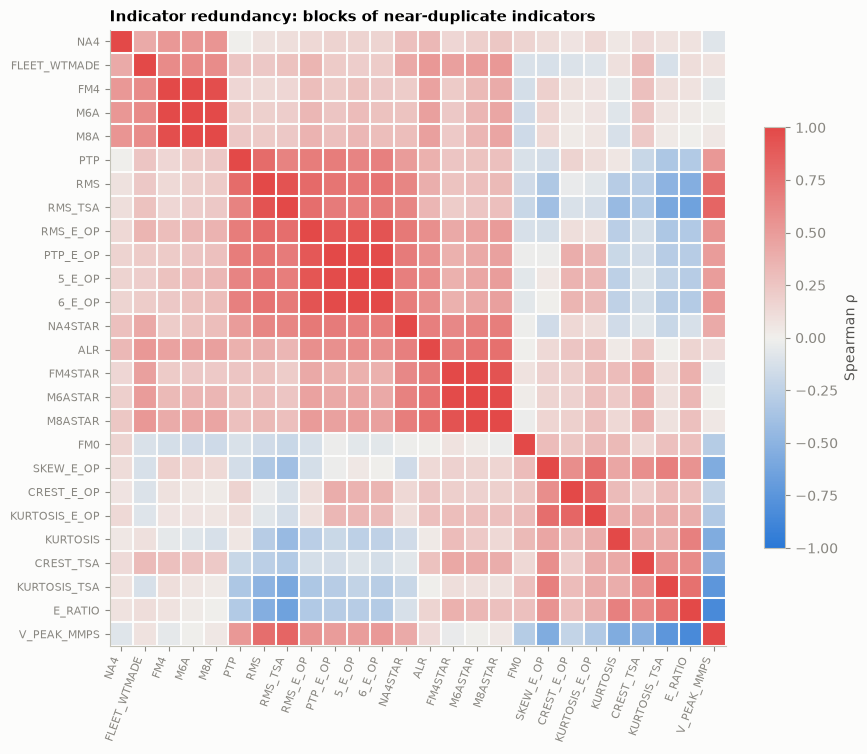

In [ ]:
# 2.7 Clustered Spearman correlation of robust-z trajectories (10-minute medians, all gears pooled)
P = pd.concat([Zs[g][CI_ALL].groupby((Zs[g].hours * 6).astype(int)).median() for g in ORDER_G]).dropna()
Cm = P.rank().corr().values
order = leaves_list(linkage(1 - np.abs(Cm[np.triu_indices(len(CI_ALL), 1)]), "average"))
labels = [CI_ALL[i][3:].upper() for i in order]
div = LinearSegmentedColormap.from_list("div", [BLUE, "#f0efec", "#e34948"])
fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(Cm[np.ix_(order, order)], cmap=div, vmin=-1, vmax=1)
ax.set_xticks(range(len(labels)), labels, rotation=70, ha="right", fontsize=8)
ax.set_yticks(range(len(labels)), labels, fontsize=8)
ax.set_xticks(np.arange(-.5, len(labels)), minor=True); ax.set_yticks(np.arange(-.5, len(labels)), minor=True)
ax.grid(which="minor", color=SURFACE, lw=1.5); ax.grid(which="major", visible=False); ax.tick_params(which="minor", length=0)
fig.colorbar(im, ax=ax, shrink=0.6, label="Spearman ρ")
ax.set_title("Indicator redundancy: blocks of near-duplicate indicators")
plt.tight_layout(); plt.show()

## 2.8 Oil debris

The DM4500 counter is cumulative over a run (it is reset between runs). Larger ferrous particles (bins 2–7) are
the ones that should respond to spalling. Debris is a second, non-vibration sensor and serves as a baseline in
Part 3.

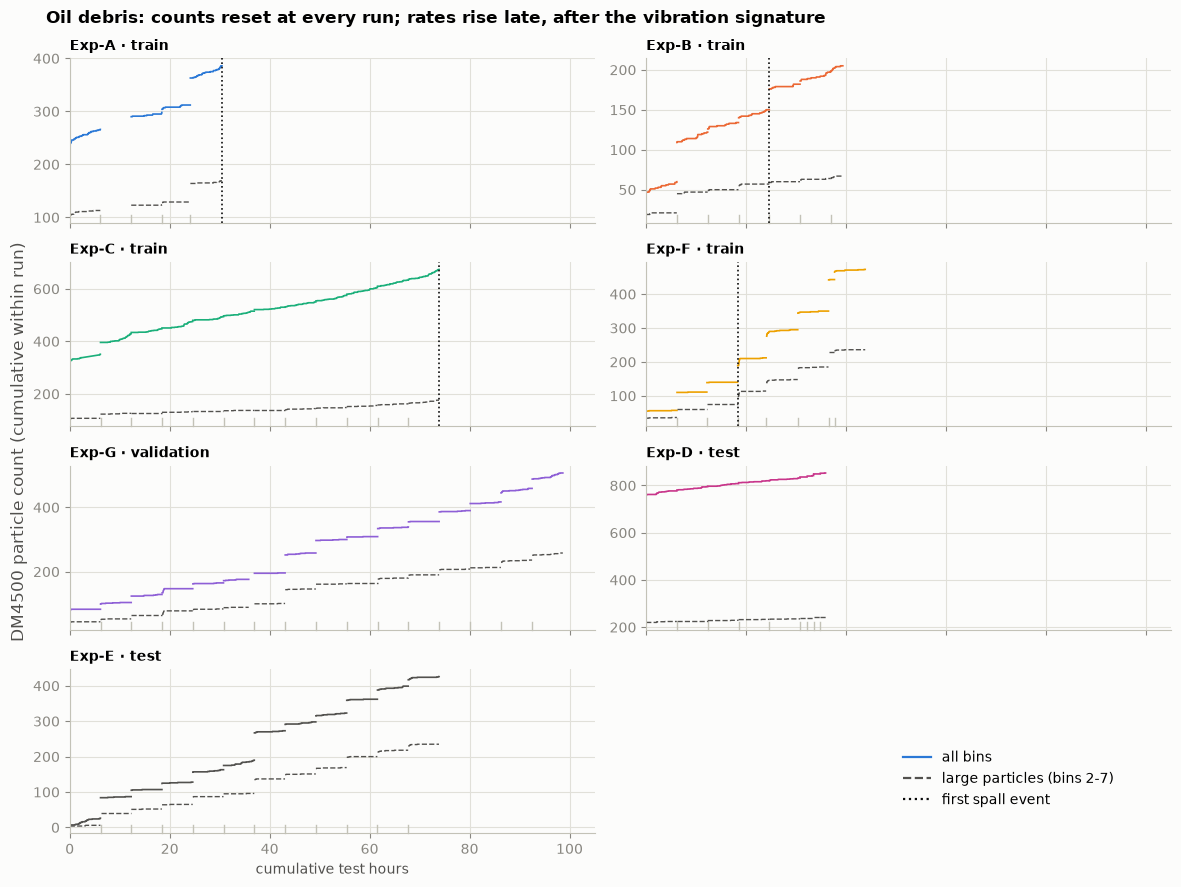

In [ ]:
# 2.8 Cumulative DM4500 particle count per gear, with run boundaries
PART["dm_total"] = PART[[f"dm4500_bin_{i}" for i in range(8)]].sum(axis=1)
PART["dm_large"] = PART[[f"dm4500_bin_{i}" for i in range(2, 8)]].sum(axis=1)
PART["hours"] = PART.file.map(S1.groupby("file").test_hours.min())
fig, axes = plt.subplots(4, 2, figsize=(12, 9), sharex=True)
for ax, g in zip(axes.flat, ORDER_G):
    d = PART[PART.experiment == g].dropna(subset=["hours"]).sort_values("hours")
    for _, r in d.groupby("run_num"):
        ax.plot(r.hours, r.dm_total, color=GEAR_C[g[-1]], lw=1.2)
        ax.plot(r.hours, r.dm_large, color=INK2, lw=1, ls="--")
    run_ticks(ax, g)
    if g in ONSET_H:
        ax.axvline(ONSET_H[g], color=INK, lw=1.2, ls=":")
    ax.set_title(f"{g} · {gear_table.loc[g, 'split']}", fontsize=10)
axes.flat[-1].axis("off"); axes.flat[0].set_xlim(0, 105)
for ax in axes[-1]: ax.set_xlabel("cumulative test hours")
fig.supylabel("DM4500 particle count (cumulative within run)", color=INK2)
fig.legend(handles=[Line2D([], [], color=BLUE, label="all bins"), Line2D([], [], color=INK2, ls="--", label="large particles (bins 2-7)"),
                    Line2D([], [], color=INK, ls=":", label="first spall event")], loc="lower right", bbox_to_anchor=(0.95, 0.08))
fig.suptitle("Oil debris: counts reset at every run; rates rise late, after the vibration signature", x=0.05, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()

## 2.9 Photos and labels

Between runs, every tooth was photographed (about 2,100 photos, not shipped). Early in the project we scored each
photo automatically with a **texture score** (`tex`: share of high-gradient pixels on the flank below the contact
band) to find candidate damaged teeth; the final per-tooth condition labels came later and supersede it. The grid
below shows the final condition labels per gear; the boxplot shows how the automated proxy relates to them.

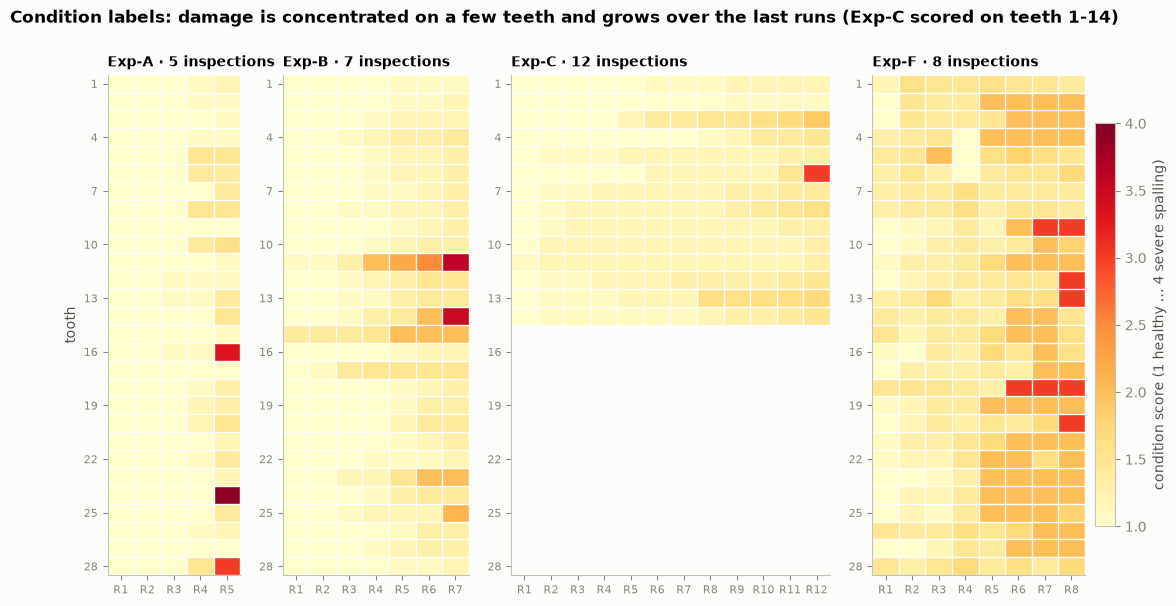

In [ ]:
# 2.9a Tooth x run-end condition labels for the four training gears
fig, axes = plt.subplots(1, 4, figsize=(13, 6.5), gridspec_kw=dict(width_ratios=[5, 7, 12, 8]))
for ax, g in zip(axes, TRAIN_GEARS):
    M = LAB[LAB.experiment == g].pivot(index="tooth", columns="run_num", values="score").reindex(range(1, 29))
    im = ax.imshow(np.ma.masked_invalid(M.values), cmap="YlOrRd", vmin=1, vmax=4, aspect="auto", interpolation="none")
    ax.set_xticks(range(M.shape[1]), [f"R{c}" for c in M.columns], fontsize=8)
    ax.set_yticks(range(0, 28, 3), [str(t + 1) for t in range(0, 28, 3)], fontsize=8)
    ax.set_xticks(np.arange(-.5, M.shape[1]), minor=True); ax.set_yticks(np.arange(-.5, 28), minor=True)
    ax.grid(which="minor", color=SURFACE, lw=1); ax.grid(which="major", visible=False); ax.tick_params(which="minor", length=0)
    ax.set_title(f"{g} · {M.shape[1]} inspections", fontsize=10)
axes[0].set_ylabel("tooth")
fig.colorbar(im, ax=axes, fraction=0.02, pad=0.01, label="condition score (1 healthy … 4 severe spalling)")
fig.suptitle("Condition labels: damage is concentrated on a few teeth and grows over the last runs (Exp-C scored on teeth 1-14)",
             x=0.05, ha="left", fontweight="bold")
plt.show()

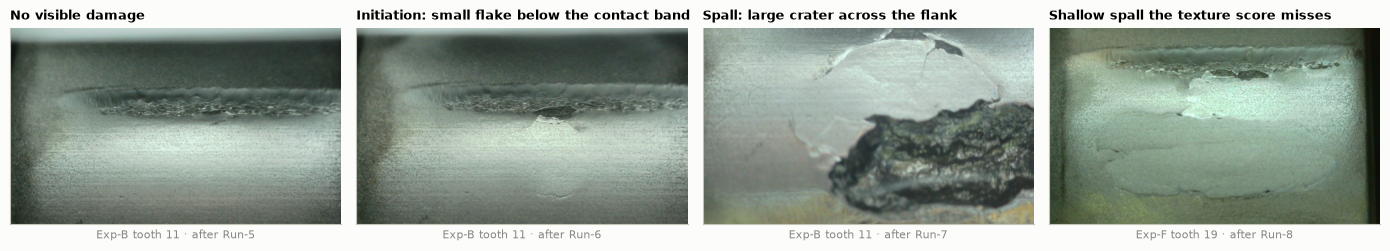

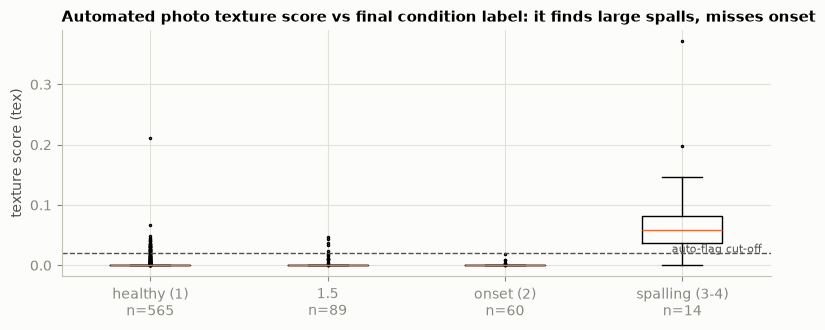

In [ ]:
# 2.9b Rubric photos (shipped) and the automated texture score against the final labels
RUBRIC = [("No visible damage", "Exp-B tooth 11 · after Run-5", "Exp-B_Run-5_All_Teeth_Tooth_11.jpg"),
          ("Initiation: small flake below the contact band", "Exp-B tooth 11 · after Run-6", "Exp-B_Run-6_All_Teeth_Tooth_11.jpg"),
          ("Spall: large crater across the flank", "Exp-B tooth 11 · after Run-7", "Exp-B_Run-7_All_Teeth_Tooth_11.jpg"),
          ("Shallow spall the texture score misses", "Exp-F tooth 19 · after Run-8", "Exp-F_Run-8_Tooth_19.jpg")]
fig, axes = plt.subplots(1, 4, figsize=(14, 3.4))
for ax, (title, sub, name) in zip(axes, RUBRIC):
    im = Image.open(DATA / "train" / "photos_sample" / name); w, h = im.size
    ax.imshow(im.crop((int(w * .12), int(h * .15), int(w * .88), int(h * .95))).reduce(4))
    ax.set_title(title, fontsize=9); ax.set_xlabel(sub, fontsize=8, color=MUTED)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
plt.tight_layout(); plt.show()

PH = pd.read_csv(DATA / "eda" / "photo_proxy.csv")
m = PH.merge(LAB, left_on=["experiment", "tooth", "insp_order"], right_on=["experiment", "tooth", "run_num"])
m["grade"] = pd.cut(m.score, [0.99, 1.49, 1.99, 2.99, 4.01], labels=["healthy (1)", "1.5", "onset (2)", "spalling (3-4)"])
fig, ax = plt.subplots(figsize=(8, 3.4))
groups = [m.loc[m.grade == k, "tex"].values for k in m.grade.cat.categories]
ax.boxplot(groups, tick_labels=[f"{k}\nn={len(v)}" for k, v in zip(m.grade.cat.categories, groups)], showfliers=True,
           flierprops=dict(marker=".", ms=3, color=MUTED), medianprops=dict(color=ORANGE))
ax.axhline(0.02, color=INK2, ls="--", lw=1); ax.text(4.45, 0.021, "auto-flag cut-off", fontsize=8, color=INK2, ha="right")
ax.set_ylabel("texture score (tex)"); ax.set_title("Automated photo texture score vs final condition label: it finds large spalls, misses onset")
plt.tight_layout(); plt.show()

---
# Part 3 · Unsupervised learning

## 3.1 Framing

Damage labels are scarce (one inspection per run, 32 labelled run ends in total) and a monitoring system on a new
gear has none. We therefore frame the problem as **novelty detection relative to a healthy reference**: every model
is fit *only* on minutes in which a gear is known to be healthy, and damage is scored as the distance of later
minutes from that healthy state. We rely on two facts of the test design, not on labels: every gear starts healthy,
and every training gear was run until it spalled. Labels are used only to evaluate.

The pipeline, applied inside leave-one-gear-out (LOGO) folds:

1. **Steady-state minutes** (Part 2.1) for the 12 gear-mesh CIs with a damage interpretation.
2. **Condition correction.** log|CI|, then regress out temperature and torque per gear.
3. **Per-gear robust standardisation** on the gear's own **healthy window (0.5–6 h, inside Run 1)**: median/MAD
   z-scores, "how many healthy standard deviations is this gear from its own normal?"
4. **Healthy-state model** fit on the pooled healthy-window minutes of the *training* gears only.
5. **Run-end health index (HI)**: the 90th percentile of the minute scores over the last 60 steady minutes of each
   run, made non-decreasing per gear (spalls do not heal) with isotonic regression.

Two feature sets are compared: **all 12 CIs** and the **4 tooth-damage CIs** (FM4, M6A, M8A, NA4), which respond to
localised impulsiveness once the regular mesh harmonics are removed.

In [ ]:
# 3.1 Pipeline constants and stages 1-3 (steady minutes -> condition correction -> per-gear healthy z-scores)
FEATS = ["ci_fm4", "ci_m6a", "ci_m8a", "ci_na4", "ci_e_ratio", "ci_kurtosis_tsa", "ci_rms_tsa", "ci_alr",
         "ci_fm0", "ci_crest_tsa", "ci_kurtosis_e_op", "ci_rms_e_op"]          # 12 gear-mesh CIs
TOOTH = ["ci_fm4", "ci_m6a", "ci_m8a", "ci_na4"]                                # localised tooth-damage CIs
COND = ["ctx_temperature", "ctx_pau_torque"]
BREAK_IN_H, BASE_H = 0.5, 6.0        # healthy window [0.5 h, 6 h]: inside run 1 of every gear, after run-in
TAIL_MIN, TAIL_Q = 60, 0.9           # run-end value = 90th percentile of the HI over the last 60 steady minutes
MAX_DAMAGE = 3.0                     # label scale: 4 (severe) - 1 (healthy)
DEBRIS_BINS = [f"dm4500_bin_{i}" for i in range(2, 8)]

def load_minutes(lf, steady=True):
    """1-s rows -> steady-state filter -> 1-minute medians of the model features and conditions."""
    lf = lf.copy()
    lf.loc[(lf.experiment == "Exp-A") & (lf.run_num == 2), [c for c in lf if c.startswith(("ci_", "ctx_"))]] = np.nan
    if steady:
        nom_t = lf.groupby("experiment").ctx_pau_torque.transform("median")
        lf = lf[(lf.ctx_pau_speed.sub(1400).abs() < 20) & (lf.ctx_pau_torque.sub(nom_t).abs() < 0.05 * nom_t)]
    lf = lf.assign(minute=(lf.test_hours * 60).astype(int))
    m = lf.groupby(["experiment", "run_num", "minute"])[FEATS + COND].median().reset_index()
    m["hours"] = (m.minute + 0.5) / 60
    return m.dropna(subset=FEATS + COND)

def run_ends(lf):
    return lf.groupby(["experiment", "run_num"]).test_hours.max().rename("end_h").reset_index()

def load_debris(pt):
    """Large-particle count rate per run (particles/hour) from the cumulative DM4500 counters."""
    p = pt.sort_values(["experiment", "timestamp"])
    p = p[~((p.experiment == "Exp-A") & (p.run_num == 2))].copy()
    p["dm"] = p[DEBRIS_BINS].sum(axis=1)
    g = p.groupby(["experiment", "run_num"]).agg(c0=("dm", "first"), c1=("dm", "last"), t0=("timestamp", "first"), t1=("timestamp", "last"))
    hrs = (g.t1 - g.t0).dt.total_seconds() / 3600
    return ((g.c1 - g.c0) / hrs.clip(lower=0.25)).rename("debris_rate").reset_index()

def condition_correct(m, base_h=BASE_H, break_in_h=BREAK_IN_H):
    """log|CI| with temperature/torque regressed out, scaled (median/MAD) on each gear's own healthy window."""
    out = []
    for _, g in m.groupby("experiment"):
        X = np.log(g[FEATS].abs().to_numpy() + 1e-9)
        C = g[COND].to_numpy()
        base = ((g.hours > break_in_h) & (g.hours < base_h)).to_numpy()
        mu, sd = C[base].mean(0), C[base].std(0) + 1e-9
        T = np.c_[np.ones(len(C)), (C - mu) / sd]
        beta = np.linalg.lstsq(T[base], X[base], rcond=None)[0]
        R = X - T @ beta
        med = np.median(R[base], 0)
        mad = np.median(np.abs(R[base] - med), 0) * 1.4826
        z = pd.DataFrame((R - med) / np.where(mad > 0, mad, 1), columns=FEATS, index=g.index)
        z[["experiment", "run_num", "hours"]] = g[["experiment", "run_num", "hours"]]
        z["base"] = base
        out.append(z)
    return pd.concat(out)

MIN = {s: load_minutes(LF[s]) for s in SPLITS}
Z = {s: condition_correct(MIN[s]) for s in SPLITS}
ENDS = {s: run_ends(LF[s]) for s in SPLITS}
DEBRIS = load_debris(PT["train"])
z_tr, ends_tr = Z["train"], ENDS["train"]
print("steady minutes per training gear:", MIN["train"].groupby("experiment").size().to_dict())
print("healthy-window (baseline) minutes:", z_tr.groupby("experiment").base.sum().to_dict())

steady minutes per training gear: {'Exp-A': 1412, 'Exp-B': 2300, 'Exp-C': 4324, 'Exp-F': 2550}
healthy-window (baseline) minutes: {'Exp-A': 330, 'Exp-B': 330, 'Exp-C': 330, 'Exp-F': 330}


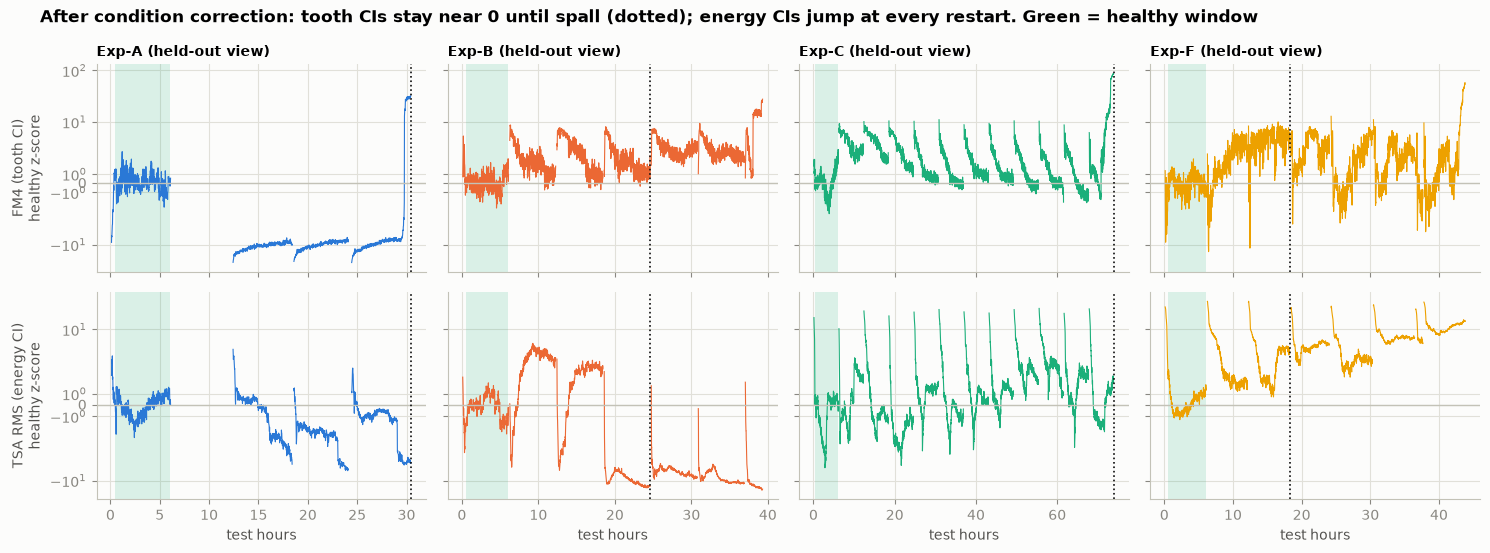

In [ ]:
# 3.1 What condition correction does: a tooth CI and an energy CI as healthy z-scores, per training gear
fig, axes = plt.subplots(2, 4, figsize=(15, 5.6), sharex="col", sharey="row")
for j, g in enumerate(TRAIN_GEARS):
    zg = z_tr[z_tr.experiment == g]
    for i, (c, name) in enumerate([("ci_fm4", "FM4 (tooth CI)"), ("ci_rms_tsa", "TSA RMS (energy CI)")]):
        ax = axes[i, j]
        for _, r in zg.groupby("run_num"):
            ax.plot(r.hours, r[c], color=GEAR_C[g[-1]], lw=0.8)
        ax.axvspan(BREAK_IN_H, BASE_H, color=AQUA, alpha=0.15, lw=0)
        ax.axhline(0, color=AXIS, lw=1)
        if g in ONSET_H:
            ax.axvline(ONSET_H[g], color=INK, lw=1.2, ls=":")
        ax.set_yscale("symlog", linthresh=5, linscale=0.8)
        if i == 0: ax.set_title(f"{g} (held-out view)", fontsize=10)
        if j == 0: ax.set_ylabel(f"{name}\nhealthy z-score")
        if i == 1: ax.set_xlabel("test hours")
fig.suptitle("After condition correction: tooth CIs stay near 0 until spall (dotted); energy CIs jump at every restart. Green = healthy window",
             x=0.03, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()

## 3.2 Three method families and a "no-model" control

| Family | Mechanism | Score | Why it fits |
|---|---|---|---|
| **Gaussian density** | Multivariate Gaussian on healthy minutes, Ledoit–Wolf shrinkage covariance | Mahalanobis distance √(d²/p) on all 12 CIs (`maha`) or on the 4 tooth CIs, upward departures only (`tooth_maha`) | CIs are strongly correlated; Mahalanobis discounts correlated movement; shrinkage keeps a 12×12 covariance stable on ~1,000 minutes |
| **Linear subspace** | PCA on healthy minutes keeping 95 % of variance (7–8 of 12 components) | Squared prediction error (SPE / Q-statistic): residual off the healthy subspace (`spe`) | Catches a *new* direction of variation even when each CI alone is in range |
| **Tree ensemble** | Isolation Forest, 200 trees, scikit-learn defaults | −`score_samples`: points that random splits isolate quickly are anomalous | No distributional or linearity assumption; handles heavy tails and multimodality |
| **No-model control** | directional z-score aggregates | `zpos` RMS of positive all-CI z; `zmax` largest |z|; `tooth` mean of positive tooth-CI z | Uses the healthy reference but fits no covariance or trees. `tooth` is the HI we committed to in advance and submitted |

Every setting was fixed before evaluation (healthy window 0.5–6 h, tail 60 min / 90th percentile, PCA 95 %,
Isolation Forest defaults with seed 696). The **alarm threshold** of a method is the 95th percentile of its score on
the fit gears' healthy minutes, so about 5 % of healthy minutes alarm by construction.

In [ ]:
# 3.2 Stage 4-5: healthy-state models, run-end scores, and the evaluation helpers
class HealthyModel:
    """Healthy-state models fit on pooled baseline minutes of the training gears only."""
    def __init__(self, tooth=TOOTH, feats=FEATS):
        self.tooth, self.feats = tooth, feats

    def fit(self, z):
        B = z.loc[z.base, self.feats].to_numpy()
        self.lw = LedoitWolf().fit(B)
        self.lw_t = LedoitWolf().fit(z.loc[z.base, self.tooth].to_numpy())
        self.pca = PCA(n_components=0.95, svd_solver="full").fit(B)
        R = B - self.pca.inverse_transform(self.pca.transform(B))
        self.spe_scale = np.median((R**2).sum(1))
        return self

    def score(self, z):
        X = z[self.feats].to_numpy()
        R = X - self.pca.inverse_transform(self.pca.transform(X))
        s = z[["experiment", "run_num", "hours"]].copy()
        s["maha"] = np.sqrt(self.lw.mahalanobis(X) / len(self.feats))
        s["spe"] = np.sqrt((R**2).sum(1) / self.spe_scale)
        s["zpos"] = np.sqrt((np.clip(X, 0, None) ** 2).mean(1))      # directional: damage raises the CIs
        s["zmax"] = np.abs(X).max(1)
        T = z[self.tooth].to_numpy()
        s["tooth"] = np.clip(T, 0, None).mean(1)
        s["tooth_maha"] = np.sqrt(self.lw_t.mahalanobis(T) / len(self.tooth)) * (T.mean(1) > 0)
        return s

class IForestModel:
    """Isolation Forest on the 12 condition-corrected CIs, fit on baseline minutes; returns one score column."""
    def fit(self, z):
        self.m = IsolationForest(n_estimators=200, random_state=SEED).fit(z.loc[z.base, FEATS].to_numpy())
        return self

    def score(self, z):
        s = z[["experiment", "run_num", "hours"]].copy()
        s["iforest"] = -self.m.score_samples(z[FEATS].to_numpy())
        return s

HI_COLS = ["maha", "spe", "zpos", "zmax", "tooth", "tooth_maha"]

def _iso(v):
    return pd.Series(IsotonicRegression().fit_transform(np.arange(len(v)), v.to_numpy()), index=v.index)

def run_end_scores(s, ends, cols, monotone="iso", tail=TAIL_MIN, q=TAIL_Q):
    """One value per run end: q-quantile of the last `tail` minutes, carried forward, then made monotone per gear
    ("iso" = isotonic fit, "cummax" = causal running maximum, "none" = raw)."""
    t = (s.sort_values("hours").groupby(["experiment", "run_num"]).tail(tail)
          .groupby(["experiment", "run_num"])[cols].quantile(q).reset_index())
    r = ends.merge(t, on=["experiment", "run_num"], how="left").sort_values(["experiment", "run_num"])
    r[cols] = r.groupby("experiment")[cols].ffill().fillna(0)
    if monotone == "cummax":
        r[cols] = r.groupby("experiment")[cols].cummax()
    elif monotone == "iso":
        r[cols] = r.groupby("experiment")[cols].transform(_iso)
    return r

def label_damage(ends):
    """Mean tooth damage after each run from the condition labels: mean over teeth of (score - 1)."""
    d = LAB.assign(ex=lambda x: x.score - 1).groupby(["experiment", "run_num"]).ex.mean()
    return d.reindex(pd.MultiIndex.from_frame(ends[["experiment", "run_num"]])).to_numpy(dtype=float)

def challenge_score(pred, truth, scale=MAX_DAMAGE):
    """Approximation of the organisers' metric: MSE after the best monotone (isotonic) map of pred onto truth/scale,
    with ONE map shared by all gears, plus Spearman rho."""
    pred, truth = np.asarray(pred, float), np.asarray(truth, float) / scale
    fit = IsotonicRegression(out_of_bounds="clip").fit(pred, truth).predict(pred)
    return dict(mse_pooled=float(np.mean((fit - truth) ** 2)), spearman=float(spearmanr(pred, truth)[0]))

def folds(gears=TRAIN_GEARS):
    return [([g for g in gears if g != h], h) for h in gears]

def logo_scores(z, alarm_q=0.95):
    """Leave-one-gear-out per-minute scores for every HI column and Isolation Forest, plus each fold's alarm
    threshold (the alarm_q quantile of the score on the fit gears' own baseline minutes)."""
    parts, thr = [], {}
    for train, held in folds():
        fit, zh = z[z.experiment.isin(train)], z[z.experiment == held]
        hm, ifm = HealthyModel().fit(fit), IForestModel().fit(fit)
        s = hm.score(zh).assign(iforest=ifm.score(zh).iforest)
        parts.append(s)
        b = hm.score(fit[fit.base]).assign(iforest=ifm.score(fit[fit.base]).iforest)
        thr[held] = b[HI_COLS + ["iforest"]].quantile(alarm_q)
    return pd.concat(parts), pd.DataFrame(thr).T

print("defined: HealthyModel, IForestModel, run_end_scores, label_damage, challenge_score, logo_scores")

defined: HealthyModel, IForestModel, run_end_scores, label_damage, challenge_score, logo_scores


## 3.3 Intuition: the three families have different blind spots

A toy example before the real data. Healthy data has **two operating modes** on one correlated line. We score three
test points: **P1** between the modes (on the line, at the healthy mean, but no healthy data was ever there),
**P2** beyond the end of the line, **P3** just off the line. Red contour = alarm boundary (95th percentile of the
healthy points' own scores); X = alarm.

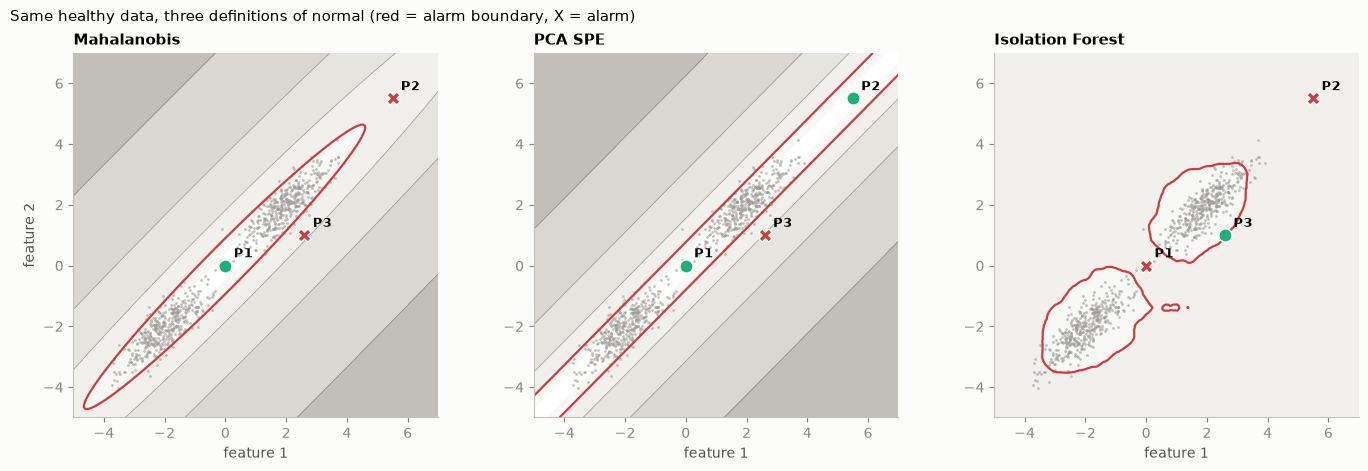

,Mahalanobis,PCA SPE,Isolation Forest
score ÷ alarm threshold,,,
P1 between modes,0.02,0.02,1.04
P2 beyond the line,1.20,0.06,1.23
P3 off the line,1.80,2.06,0.98


In [ ]:
# 3.3 Toy example: Mahalanobis vs PCA residual vs Isolation Forest on two-mode healthy data
class Maha2:
    name = "Mahalanobis"
    def fit(self, B): self.m = LedoitWolf().fit(B); return self
    def score(self, X): return np.sqrt(self.m.mahalanobis(X))

class SPE2:
    name = "PCA SPE"
    def fit(self, B): self.p = PCA(n_components=1).fit(B); return self
    def score(self, X):
        R = X - self.p.inverse_transform(self.p.transform(X)); return np.sqrt((R**2).sum(1))

class IF2:
    name = "Isolation Forest"
    def fit(self, B): self.m = IsolationForest(n_estimators=200, random_state=SEED).fit(B); return self
    def score(self, X): return -self.m.score_samples(X)

def fit_scaled(M, B):
    m = M().fit(B); m.thr = np.percentile(m.score(B), 95); m.rel = lambda X, m=m: m.score(X) / m.thr; return m

def grid(lo, hi, n=250):
    gx, gy = np.meshgrid(np.linspace(lo[0], hi[0], n), np.linspace(lo[1], hi[1], n))
    return gx, gy, np.c_[gx.ravel(), gy.ravel()]

LEVELS = [0, 0.5, 1, 2, 4, 8, 16, 1e9]
def draw_field(ax, gx, gy, S):
    ax.contourf(gx, gy, S, levels=LEVELS, cmap=GREYS, norm=BoundaryNorm(LEVELS, GREYS.N))
    ax.contour(gx, gy, S, levels=[2, 4, 8], colors=INK2, linewidths=0.5, alpha=0.5)
    ax.contour(gx, gy, S, levels=[1], colors=THR, linewidths=1.6)

rng = np.random.default_rng(SEED)
cov = [[0.5, 0.42], [0.42, 0.5]]
B_toy = np.vstack([rng.multivariate_normal([-2, -2], cov, 400), rng.multivariate_normal([2, 2], cov, 400)])
P_toy = {"P1 between modes": (0.0, 0.0), "P2 beyond the line": (5.5, 5.5), "P3 off the line": (2.6, 1.0)}
P_xy = np.array(list(P_toy.values()))
gx, gy, G = grid((-5, -5), (7, 7))
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6), layout="constrained")
rows = {}
for ax, M in zip(axes, [Maha2, SPE2, IF2]):
    m = fit_scaled(M, B_toy)
    S = m.rel(G).reshape(gx.shape)
    draw_field(ax, gx, gy, median_filter(S, size=5) if m.name == "Isolation Forest" else S)
    ax.scatter(*B_toy.T, s=4, color=BASE, alpha=0.6, lw=0)
    rel = m.rel(P_xy); rows[m.name] = rel
    for (label, (x, y)), r in zip(P_toy.items(), rel):
        ax.scatter(x, y, s=90, marker="X" if r > 1 else "o", color=THR if r > 1 else AQUA, edgecolor="white", lw=1, zorder=5)
        ax.annotate(label.split()[0], (x, y), xytext=(6, 6), textcoords="offset points", fontsize=9, fontweight="bold")
    ax.set_title(m.name); ax.set(xlim=(-5, 7), ylim=(-5, 7), aspect="equal", xlabel="feature 1"); ax.grid(False)
axes[0].set_ylabel("feature 2")
fig.suptitle("Same healthy data, three definitions of normal (red = alarm boundary, X = alarm)", x=0.01, ha="left", fontsize=11)
plt.show()
pd.DataFrame(rows, index=list(P_toy)).round(2).rename_axis("score ÷ alarm threshold")

Each method misses a different point. **Mahalanobis** fits one ellipse over both modes and calls P1
(the healthy mean) perfectly normal. **PCA SPE** only measures distance *off* the line, so it misses P1 and P2 and
scores P3's small sideways step highest. **Isolation Forest** wraps each mode separately and is the only one to flag
P1, but its score has a ceiling: a point cannot be isolated in fewer than one cut, so even an extreme outlier scores
only a few times the threshold.

## 3.4 Leave-one-gear-out scores on the real data

The independent unit is the **gear**, not the minute: minutes of one gear share its rig, mounting, load, baseline
signature and damage path, so a random minute split would leak the gear's identity. In each fold the healthy models
are fit on three gears' healthy windows and every minute of the fourth gear is scored. Every score is divided by
that fold's alarm threshold, so **1 = alarm** in every plot below.

In [ ]:
# 3.4 LOGO per-minute scores (relative to the 95th-percentile alarm threshold) and run-end HIs for every method
FAMILIES = {"Mahalanobis": "maha", "PCA SPE": "spe", "Isolation Forest": "iforest", "Tooth-CI Mahalanobis": "tooth_maha"}
ALL_COLS = HI_COLS + ["iforest"]
s_logo, thr95 = logo_scores(z_tr, 0.95)
minutes = s_logo.copy()
for c in ALL_COLS:
    minutes[c] = s_logo[c] / s_logo.experiment.map(thr95[c])
minutes = minutes.merge(lab_runs[["experiment", "run_num", "mean_ex", "max"]], on=["experiment", "run_num"], how="left")

run_iso = run_end_scores(s_logo, ends_tr, ALL_COLS, "iso")        # smoothed (for the offline challenge metric)
run_cmx = run_end_scores(s_logo, ends_tr, ALL_COLS, "cummax")     # causal (for alarms and lead time)
for r in (run_iso, run_cmx):
    for c in ALL_COLS:
        r[c + "_rel"] = r[c] / r.experiment.map(thr95[c])
run_iso["damage"] = run_cmx["damage"] = label_damage(run_iso)
run_iso = run_iso.merge(lab_runs[["experiment", "run_num", "max"]], on=["experiment", "run_num"], how="left")
run_cmx = run_cmx.merge(lab_runs[["experiment", "run_num", "max"]], on=["experiment", "run_num"], how="left")
run_iso["spall"] = run_cmx["spall"] = run_iso["max"] >= 2
print(f"{len(minutes):,} held-out minutes · {len(run_iso)} scored run ends · {int(run_iso.spall.sum())} spall run ends")
thr95.round(3)

10,586 held-out minutes · 32 scored run ends · 11 spall run ends


,maha,spe,zpos,zmax,tooth,tooth_maha,iforest
Exp-A,1.414,1.839,1.722,4.063,1.437,1.411,0.543
Exp-B,1.400,1.967,1.747,4.014,1.586,1.485,0.543
Exp-C,1.376,1.805,1.359,2.989,1.449,1.476,0.539
Exp-F,1.437,2.072,1.746,4.046,1.546,1.474,0.535


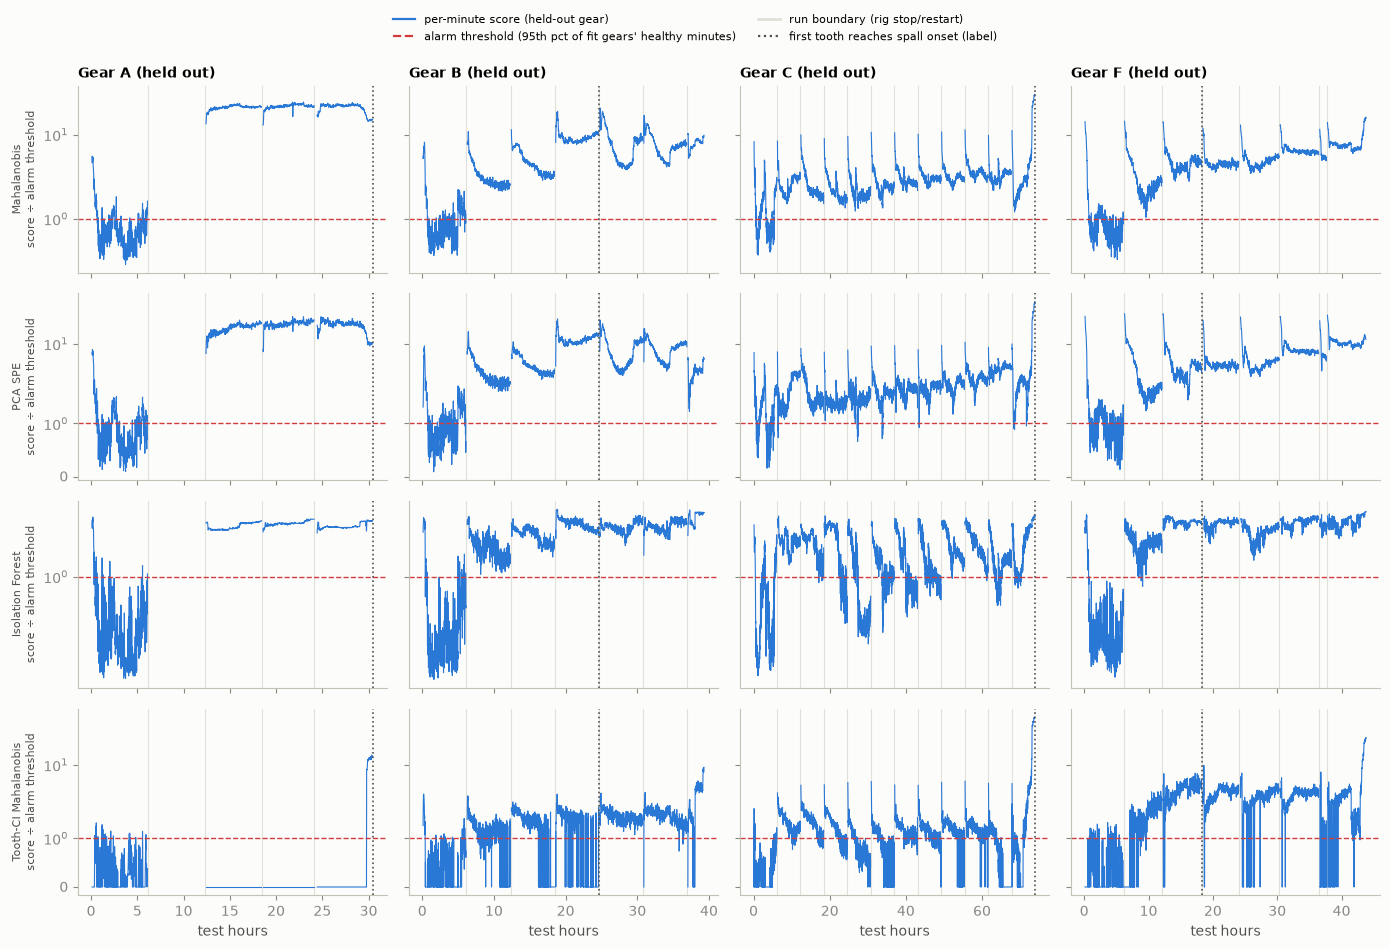

In [ ]:
# 3.4 Figure: per-minute held-out scores, one row per method family, one column per held-out gear (1 = alarm)
fig, axes = plt.subplots(len(FAMILIES), 4, figsize=(14, 9.5), sharey="row", sharex="col")
for i, (name, col) in enumerate(FAMILIES.items()):
    for j, held in enumerate(TRAIN_GEARS):
        ax = axes[i, j]
        zh = minutes[minutes.experiment == held]
        for _, g in zh.groupby("run_num"):                      # break the line at rig restarts
            ax.plot(g.hours, g[col], color=BLUE, lw=0.8)
        ax.axhline(1, color=THR, ls="--", lw=1)
        for h in ends_tr.loc[ends_tr.experiment == held, "end_h"].iloc[:-1]:
            ax.axvline(h, color=GRID, lw=0.8, zorder=0)
        if held in ONSET_H:
            ax.axvline(ONSET_H[held], color=INK2, ls=":", lw=1.2)
        ax.set_yscale("symlog", linthresh=1, linscale=0.6); ax.grid(False)
        if i == 0: ax.set_title(f"Gear {held[-1]} (held out)", fontsize=10)
        if j == 0: ax.set_ylabel(f"{name}\nscore ÷ alarm threshold", fontsize=8)
        if i == len(FAMILIES) - 1: ax.set_xlabel("test hours")
fig.legend(handles=[Line2D([], [], color=BLUE, label="per-minute score (held-out gear)"),
                    Line2D([], [], color=THR, ls="--", label="alarm threshold (95th pct of fit gears' healthy minutes)"),
                    Line2D([], [], color=GRID, lw=2, label="run boundary (rig stop/restart)"),
                    Line2D([], [], color=INK2, ls=":", label="first tooth reaches spall onset (label)")],
           loc="upper center", ncol=2, fontsize=8, bbox_to_anchor=(0.5, 1.0))
fig.tight_layout(rect=(0, 0, 1, 0.95)); plt.show()

The three all-CI models (rows 1–3) step up 10–20× above threshold at the **first rig restart** of
every gear and stay there. On Gear A this happens in Runs 3–4, while the labels say the gear was still healthy. The
tooth-CI model (row 4) stays at or below threshold on the same runs and rises only near spall onset.

## 3.5 The PCA health space

The same thing seen geometrically: held-out minutes projected on the first two principal components of the other
gears' healthy baseline, coloured by the inspected damage of their run. The scree on the right shows how many
components the 95 % rule keeps per fold.

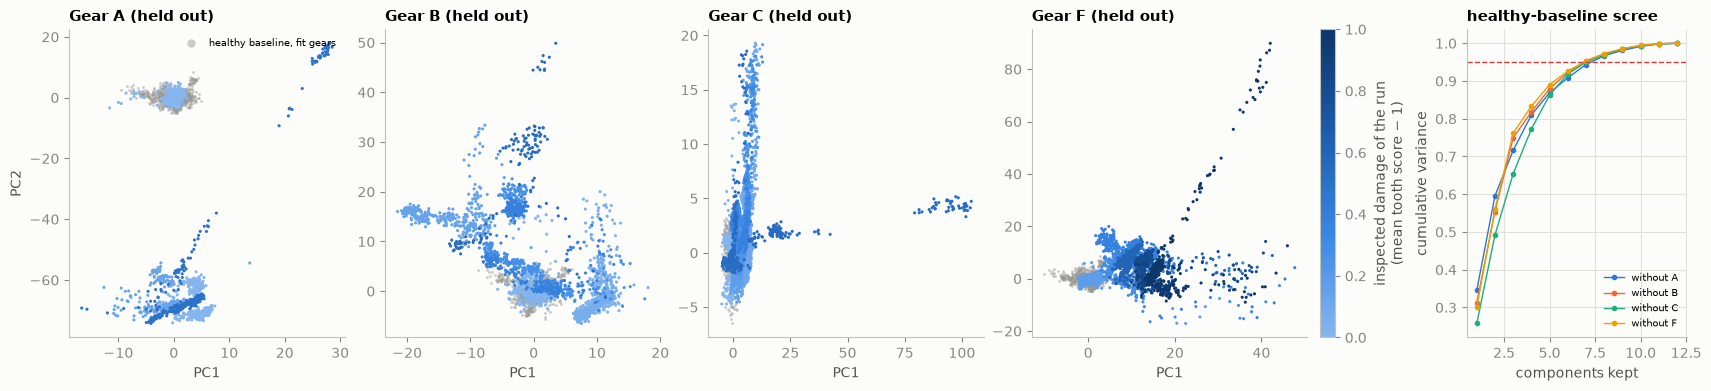

In [ ]:
# 3.5 PCA health space per fold + healthy-baseline scree
fig, axes = plt.subplots(1, 5, figsize=(17, 3.8), gridspec_kw=dict(width_ratios=[1, 1, 1, 1, 0.8]), layout="constrained")
for ax, (train, held) in zip(axes, folds()):
    hm = HealthyModel().fit(z_tr[z_tr.experiment.isin(train)])
    fit = z_tr[z_tr.experiment.isin(train) & z_tr.base]
    zh = z_tr[z_tr.experiment == held].merge(lab_runs[["experiment", "run_num", "mean_ex"]], on=["experiment", "run_num"], how="left")
    P0 = hm.pca.transform(fit[FEATS].to_numpy())[:, :2]
    Pz = hm.pca.transform(zh[FEATS].to_numpy())[:, :2]
    ax.scatter(P0[:, 0], P0[:, 1], s=4, color=BASE, alpha=0.5, lw=0, label="healthy baseline, fit gears")
    sc = ax.scatter(Pz[:, 0], Pz[:, 1], s=5, c=zh.mean_ex, cmap=BLUES, vmin=0, vmax=1, lw=0)
    ax.set(xlabel="PC1", title=f"Gear {held[-1]} (held out)"); ax.grid(False)
axes[0].set_ylabel("PC2"); axes[0].legend(fontsize=7, loc="upper right", markerscale=3)
fig.colorbar(sc, ax=list(axes[:4]), label="inspected damage of the run\n(mean tooth score − 1)", fraction=0.025, pad=0.01)
for train, held in folds():
    v = np.cumsum(PCA().fit(z_tr.loc[z_tr.experiment.isin(train) & z_tr.base, FEATS]).explained_variance_ratio_)
    axes[4].plot(range(1, len(v) + 1), v, marker="o", ms=3, lw=1, color=GEAR_C[held[-1]], label=f"without {held[-1]}")
axes[4].axhline(0.95, color=THR, ls="--", lw=1)
axes[4].set(xlabel="components kept", ylabel="cumulative variance", title="healthy-baseline scree"); axes[4].legend(fontsize=7)
plt.show()

On Gear F, damage grows along a consistent direction away from the healthy cloud. On Gear A, the
healthy post-restart runs (light) sit in the same far cluster as the spalled final run (dark): a whole-signature
shift caused by reassembly, which distance from the healthy subspace cannot separate from damage.

## 3.6 Do the three families agree?

Each held-out minute scored by one family against another. If the mechanisms led to different conclusions these
clouds would be scattered.

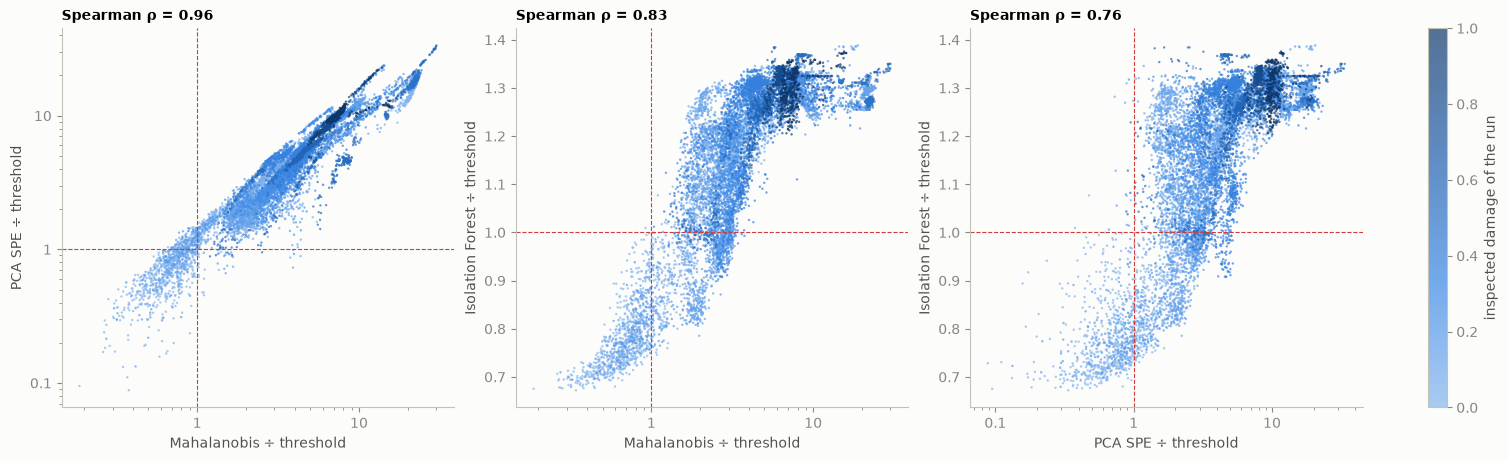

,Mahalanobis,PCA SPE,Isolation Forest,Tooth-CI Mahalanobis,damage
Mahalanobis,1.00,0.96,0.83,0.24,0.42
PCA SPE,0.96,1.00,0.76,0.16,0.42
Isolation Forest,0.83,0.76,1.00,0.52,0.46
Tooth-CI Mahalanobis,0.24,0.16,0.52,1.00,0.48
damage,0.42,0.42,0.46,0.48,1.00


In [ ]:
# 3.6 Method agreement: minute scores of one family against another, and rank correlations with damage
fams = ["Mahalanobis", "PCA SPE", "Isolation Forest"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), layout="constrained")
for ax, (a_, b_) in zip(axes, [(0, 1), (0, 2), (1, 2)]):
    x, y = minutes[FAMILIES[fams[a_]]], minutes[FAMILIES[fams[b_]]]
    sc = ax.scatter(x, y, s=3, c=minutes.mean_ex, cmap=BLUES, vmin=0, vmax=1, lw=0, alpha=0.7)
    ax.axvline(1, color=THR, ls="--", lw=0.8); ax.axhline(1, color=THR, ls="--", lw=0.8)
    ax.set(xscale="log", xlabel=f"{fams[a_]} ÷ threshold", ylabel=f"{fams[b_]} ÷ threshold")
    plain_ticks(ax.xaxis)
    if fams[b_] != "Isolation Forest":                     # IF scores have a ceiling: linear axis reads better
        ax.set_yscale("log"); plain_ticks(ax.yaxis)
    ax.set_title(f"Spearman ρ = {spearmanr(x, y).statistic:.2f}", fontsize=10); ax.grid(False)
fig.colorbar(sc, ax=axes, label="inspected damage of the run", fraction=0.02)
plt.show()

rho = (minutes[[FAMILIES[f] for f in FAMILIES] + ["mean_ex"]].corr(method="spearman")
       .rename(index={**{v: k for k, v in FAMILIES.items()}, "mean_ex": "damage"}, columns={**{v: k for k, v in FAMILIES.items()}, "mean_ex": "damage"}))
rho.round(2)

The three all-CI families rank minutes far more like **each other** (ρ = 0.76–0.96) than like damage (ρ ≈ 0.4). The
tooth-CI row shows what changes when the *input* changes instead of the model. (Minutes within a gear are not
independent, so these correlations are descriptive only.)

## 3.7 Run-end health index vs inspected damage

This is the quantity the challenge scores: one HI value per run end. The metric is the MSE after the best **monotone
rescaling shared by all gears** (isotonic regression of HI onto damage), so a good HI puts all four gears on **one**
rising curve. Baselines: **elapsed hours** ("damage grows with time") and **debris** (the large-particle rate
relative to Run 1). Alarms use the causal running maximum of the raw run-end HI against the fold's threshold.

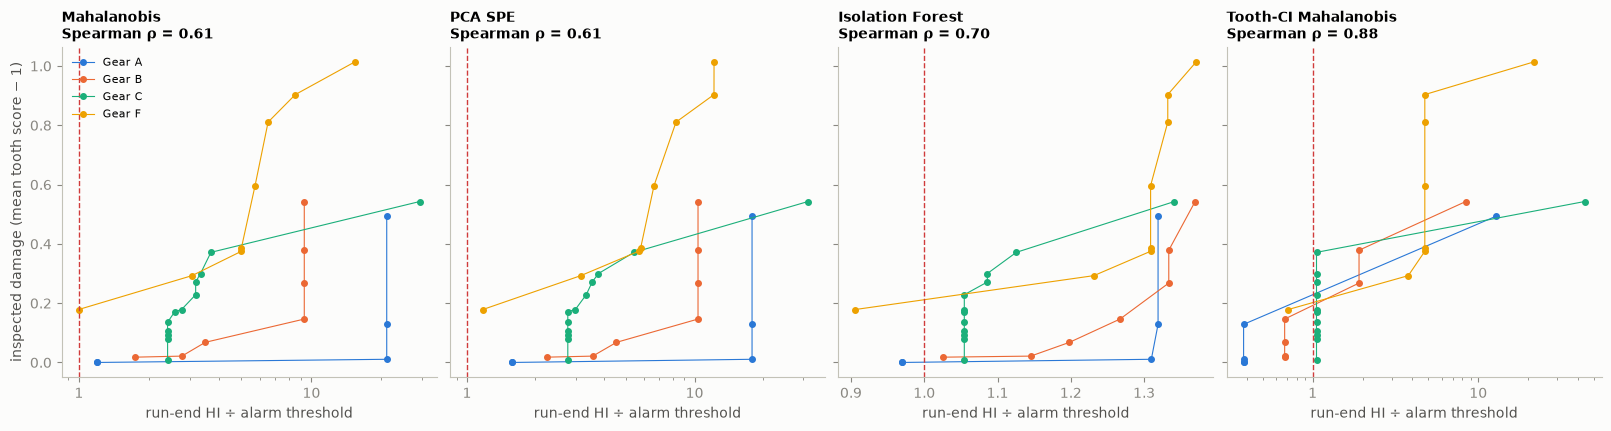

In [ ]:
# 3.7 Figure: run-end HI (smoothed) against inspected damage, one panel per family
order = ["Mahalanobis", "PCA SPE", "Isolation Forest", "Tooth-CI Mahalanobis"]
fig, axes = plt.subplots(1, 4, figsize=(16, 4.2), layout="constrained", sharey=True)
for ax, name in zip(axes, order):
    col = FAMILIES[name] + "_rel"
    for g, d in run_iso.groupby("experiment"):
        ax.plot(d[col], d.damage, "-o", ms=4, lw=0.8, color=GEAR_C[g[-1]], label=f"Gear {g[-1]}")
    ax.axvline(1, color=THR, ls="--", lw=1)
    ax.set(xscale="linear" if name == "Isolation Forest" else "log", xlabel="run-end HI ÷ alarm threshold"); ax.grid(False)
    if name != "Isolation Forest": plain_ticks(ax.xaxis)
    ax.set_title(f"{name}\nSpearman ρ = {spearmanr(run_iso[col], run_iso.damage).statistic:.2f}", fontsize=10)
axes[0].set_ylabel("inspected damage (mean tooth score − 1)"); axes[0].legend(fontsize=8)
plt.show()

In [ ]:
# 3.7 Table: every candidate HI and the two baselines under the leave-one-gear-out protocol
NAMES = {"maha": "Mahalanobis (all 12 CIs)", "spe": "PCA SPE (all CIs)", "iforest": "Isolation Forest (all CIs)",
         "zpos": "positive all-CI z RMS (no model)", "zmax": "max all-CI |z| (no model)",
         "tooth": "tooth z-score mean (no model, submitted)", "tooth_maha": "Mahalanobis (4 tooth CIs)",
         "hours": "baseline: elapsed hours", "debris": "baseline: debris rate"}
dbr = ends_tr.merge(DEBRIS, on=["experiment", "run_num"], how="left").sort_values(["experiment", "run_num"])
dbr["rel"] = dbr.debris_rate / dbr.groupby("experiment").debris_rate.transform("first")
dbr["debris"] = dbr.groupby("experiment").rel.ffill().fillna(1.0).groupby(dbr.experiment).cummax()
first_run = run_iso.run_num == run_iso.groupby("experiment").run_num.transform("min")

rows = []
for c in ALL_COLS + ["hours", "debris"]:
    if c == "hours":
        score = alarm = run_iso.end_h.to_numpy(); thr_c = run_iso.end_h[first_run].max()
    elif c == "debris":
        score = alarm = dbr.debris.to_numpy(); thr_c = dbr.debris[first_run.to_numpy()].max()
    else:
        score, alarm, thr_c = run_iso[c].to_numpy(), run_cmx[c + "_rel"].to_numpy(), 1.0
    sc = challenge_score(score, run_iso.damage)
    flag, spall = alarm > thr_c, run_iso.spall.to_numpy()
    # per-gear error under the shared isotonic map, to count on how many gears the HI beats elapsed hours
    fit = IsotonicRegression(out_of_bounds="clip").fit(score, run_iso.damage / MAX_DAMAGE).predict(score)
    per_gear = pd.Series((fit - run_iso.damage / MAX_DAMAGE) ** 2).groupby(run_iso.experiment.values).mean()
    rows.append(dict(hi=NAMES[c], key=c, **sc, caught=int((flag & spall).sum()), missed=int((~flag & spall).sum()),
                     false_alarms=int((flag & ~spall).sum()), **{f"err_{g[-1]}": v for g, v in per_gear.items()}))
results = pd.DataFrame(rows).set_index("hi")
hours_err = results.loc[NAMES["hours"], [f"err_{g[-1]}" for g in TRAIN_GEARS]]
results["beats_hours_k_of_4"] = (results[[f"err_{g[-1]}" for g in TRAIN_GEARS]] < hours_err).sum(axis=1)
results.loc[NAMES["hours"], "beats_hours_k_of_4"] = np.nan
results.drop(columns="key").sort_values("mse_pooled").round(4)

,mse_pooled,spearman,caught,missed,false_alarms,err_A,err_B,err_C,err_F,beats_hours_k_of_4
hi,,,,,,,,,,
Mahalanobis (4 tooth CIs),0.0017,0.8763,11,0,16,0.0005,0.0003,0.0016,0.0041,4.0
"tooth z-score mean (no model, submitted)",0.0018,0.8646,10,1,13,0.0005,0.0003,0.0016,0.0042,4.0
baseline: debris rate,0.0024,0.6637,6,5,11,0.0041,0.0017,0.0006,0.0046,2.0
positive all-CI z RMS (no model),0.0026,0.7196,11,0,15,0.0003,0.0041,0.0017,0.0041,3.0
Isolation Forest (all CIs),0.0032,0.6806,11,0,18,0.0057,0.0030,0.0007,0.0056,2.0
max all-CI |z| (no model),0.0040,0.6405,11,0,17,0.0078,0.0028,0.0002,0.0084,2.0
Mahalanobis (all 12 CIs),0.0041,0.6153,11,0,20,0.0078,0.0033,0.0002,0.0084,2.0
PCA SPE (all CIs),0.0042,0.6073,11,0,21,0.0089,0.0031,0.0003,0.0080,2.0
baseline: elapsed hours,0.0043,0.6613,11,0,17,0.0011,0.0006,0.0035,0.0108,NaN


Three findings:

1. **Feature representation matters more than model family.** Every model fit on all 12 CIs scores close to the
   elapsed-hours baseline. Restricting the *same* Mahalanobis model to the four tooth CIs cuts the error by more
   than half, and the tooth models beat elapsed hours on all four gears.
2. **Model families agree with each other far more than with damage.** When the input already carries the
   restart shift, the choice of density, subspace or isolation mechanism hardly matters.
3. **The all-CI "false alarms" are mostly restart shifts; the tooth-CI flags are mostly early wear** that had not yet
   reached the onset grade (the labels show damage rising on Gears B, C and F before any tooth hits 2).

## 3.8 Choosing a model without labels

In deployment there are no labels. We score each candidate HI with the Coble & Hines prognostic criteria on its raw
run-end values (LOGO, 99th-percentile thresholds), using only the test design: every gear starts healthy and was run
until it spalled.

- **monotonicity** — size-weighted share of rises minus falls (1 if the HI never falls);
- **trendability** — smallest pairwise correlation between gears' trajectories on a common 0–1 life axis;
- **prognosability** — exp(−std(final values) / mean rise): do gears end at a similar level?
- **false_alarm** — share of Run-1 minutes above the fold's alarm threshold;
- **fitness** = (monotonicity + max(trendability, 0) + prognosability) / 3 − false_alarm.

label-free rule picks: tooth  (tooth z-score mean (no model, submitted))


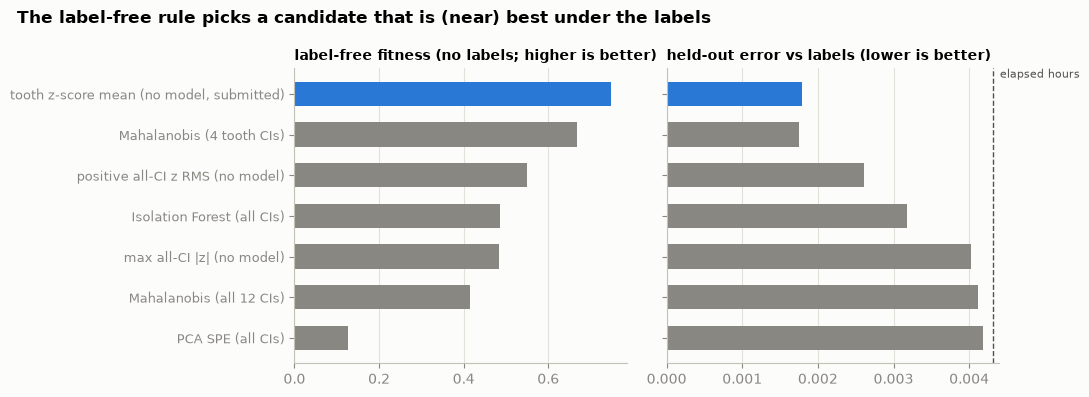

,monotonicity,trendability,prognosability,false_alarm,fitness,label_based_mse
hi,,,,,,
tooth,0.859,0.834,0.631,0.026,0.749,0.002
tooth_maha,0.791,0.798,0.514,0.034,0.667,0.002
zpos,0.829,0.446,0.644,0.089,0.550,0.003
iforest,0.724,-0.413,0.938,0.068,0.486,0.003
zmax,0.745,0.301,0.676,0.090,0.484,0.004
maha,0.802,0.317,0.656,0.176,0.415,0.004
spe,0.670,0.094,0.547,0.311,0.126,0.004


In [ ]:
# 3.8 Label-free selection criteria vs the label-based error
def label_free_table(s, thr, ends, cols):
    r = run_end_scores(s, ends, cols, "none")
    life, run1, rows = np.linspace(0, 1, 21), s[s.run_num == 1], []
    for c in cols:
        mono_, traj, first, last = [], [], [], []
        for _, g in r.groupby("experiment"):
            v = g[c].to_numpy(); d = np.diff(v)
            mono_.append(abs(d.sum()) / max(np.abs(d).sum(), 1e-9))
            traj.append(np.interp(life, g.end_h / g.end_h.max(), v)); first.append(v[0]); last.append(v[-1])
        corr = np.nan_to_num(np.corrcoef(traj), nan=0.0)
        rise = max(np.mean(np.abs(np.subtract(last, first))), 1e-9)
        alarm = run1[c] > run1.experiment.map(thr[c])
        rows.append(dict(hi=c, monotonicity=np.mean(mono_), trendability=corr[np.triu_indices(len(traj), 1)].min(),
                         prognosability=np.exp(-np.std(last) / rise), false_alarm=alarm.groupby(run1.experiment).mean().mean()))
    t = pd.DataFrame(rows).set_index("hi")
    t["fitness"] = (t.monotonicity + t.trendability.clip(lower=0) + t.prognosability) / 3 - t.false_alarm
    return t

s99, thr99 = logo_scores(z_tr, 0.99)
lf_tab = label_free_table(s99, thr99, ends_tr, ALL_COLS).sort_values("fitness", ascending=False)
lf_tab["label_based_mse"] = results.set_index("key").loc[lf_tab.index, "mse_pooled"].values
pick = lf_tab.fitness.idxmax()
print(f"label-free rule picks: {pick}  ({NAMES[pick]})")
lf_tab.to_csv(OUT / "label_free_eval.csv")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
t = lf_tab.sort_values("fitness"); y = range(len(t)); colors = [BLUE if h == pick else MUTED for h in t.index]
a1.barh(y, t.fitness, color=colors, height=0.6); a1.set_yticks(list(y), [NAMES[h] for h in t.index], fontsize=9)
a1.set_title("label-free fitness (no labels; higher is better)", fontsize=10); a1.grid(axis="y", visible=False)
a2.barh(y, t.label_based_mse, color=colors, height=0.6); a2.axvline(results.loc[NAMES["hours"], "mse_pooled"], color=INK2, ls="--", lw=1)
a2.text(results.loc[NAMES["hours"], "mse_pooled"] * 1.02, len(t) - 0.6, "elapsed hours", fontsize=8, color=INK2)
a2.set_title("held-out error vs labels (lower is better)", fontsize=10); a2.grid(axis="y", visible=False)
fig.suptitle("The label-free rule picks a candidate that is (near) best under the labels", x=0.02, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()
lf_tab.round(3)

## 3.9 Final models and challenge submissions

The healthy model is refit on the baseline windows of all four training gears and applied to the validation gear (G)
and the test gears (D, E). The submission takes, at each template time, the run-end HI of the nearest run end. We
write the fixed, pre-committed `tooth` HI (and, for comparison, the label-free pick) to `out/`.

In [ ]:
# 3.9 Fit on all training baselines, score validation/test, write submissions
hm_all = HealthyModel().fit(z_tr)
thr_all = hm_all.score(z_tr[z_tr.base])[HI_COLS].quantile(0.95)
SUBMIT = "tooth"
templates = {"validation": "example_validation_submission.csv", "test": "example_submission.csv"}
run_out = {}
for split, tmpl in templates.items():
    s = hm_all.score(Z[split])
    r = run_end_scores(s, ENDS[split], HI_COLS, "iso"); r["run_id"] = r.experiment.str[-1]
    run_out[split] = (s, r)
    for hi in dict.fromkeys([SUBMIT, pick]):
        sub = pd.read_csv(DATA / split / tmpl)
        sub["metric"] = [r.loc[r.run_id == g, [hi, "end_h"]].pipe(lambda x: x[hi].iloc[(x.end_h - t).abs().argmin()])
                         for g, t in zip(sub.run_id, sub.time)]
        sub["metric"] = sub.metric.round(4)
        name = f"{split}_submission{'' if hi == SUBMIT else '_' + hi}.csv"
        sub.to_csv(OUT / name, index=False)
        print(f"wrote out/{name}  (HI = {hi})")
pd.read_csv(OUT / "test_submission.csv").T

wrote out/validation_submission.csv  (HI = tooth)
wrote out/test_submission.csv  (HI = tooth)


,0,1,2,3,4,5,6,7,8,9,...,11,12,13,14,15,16,17,18,19,20
run_id,D,D,D,D,D,D,D,D,D,E,...,E,E,E,E,E,E,E,E,E,E
time,6.16,12.33,18.5,24.66,30.82,32.23,33.47,34.78,35.86,6.17,...,18.45,24.62,30.79,36.96,43.12,49.28,55.44,61.6,67.76,73.93
metric,0.2236,0.2236,0.2236,0.2236,0.2236,0.2236,10.7367,15.7208,27.1164,1.3277,...,5.6122,5.8981,5.8981,5.8981,5.8981,5.8981,5.8981,5.8981,6.9719,9.1583


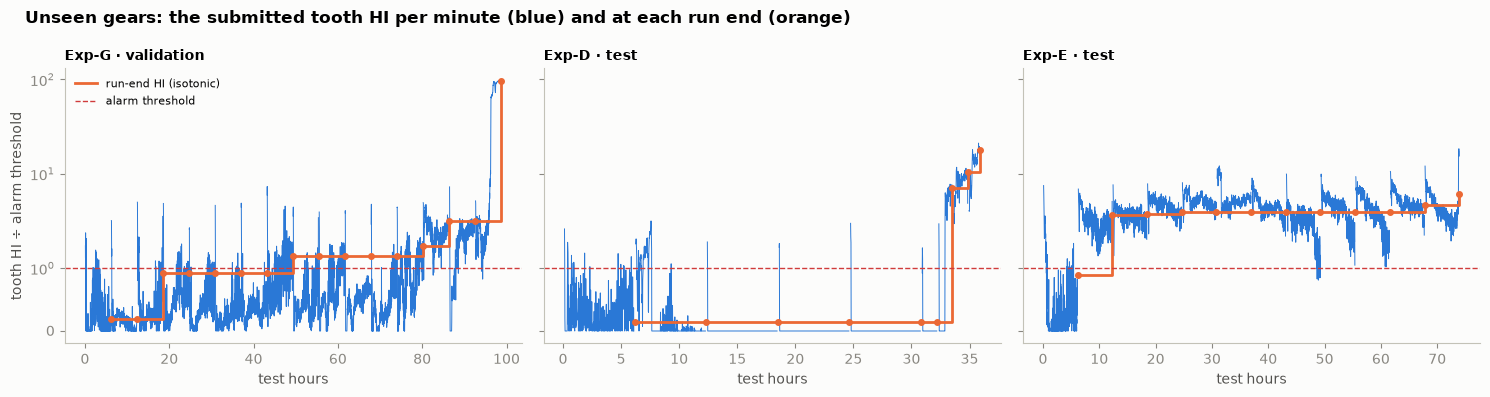

In [ ]:
# 3.9 Figure: per-minute tooth HI and run-end values on the validation and test gears
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, g in zip(axes, ["Exp-G", "Exp-D", "Exp-E"]):
    split = "validation" if g == "Exp-G" else "test"
    s, r = run_out[split]
    sg, rg = s[s.experiment == g], r[r.experiment == g]
    for _, run in sg.groupby("run_num"):
        ax.plot(run.hours, run[SUBMIT] / thr_all[SUBMIT], color=BLUE, lw=0.7)
    ax.step(rg.end_h, rg[SUBMIT] / thr_all[SUBMIT], where="post", color=ORANGE, lw=2, label="run-end HI (isotonic)")
    ax.plot(rg.end_h, rg[SUBMIT] / thr_all[SUBMIT], "o", color=ORANGE, ms=4)
    ax.axhline(1, color=THR, ls="--", lw=1, label="alarm threshold")
    ax.set_yscale("symlog", linthresh=1, linscale=0.6); ax.grid(False)
    ax.set_title(f"{g} · {split}", fontsize=10); ax.set_xlabel("test hours")
axes[0].set_ylabel("tooth HI ÷ alarm threshold"); axes[0].legend(fontsize=8, loc="upper left")
fig.suptitle("Unseen gears: the submitted tooth HI per minute (blue) and at each run end (orange)", x=0.02, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()

## Takeaways and where to go next

- **Data.** 3 splits, 7 gears, ~1.4 M one-second rows; one duplicate run (Exp-A Run-2) removed; ~95 % of seconds are
  steady state. Labels: per-tooth condition scores after every training run (32 run ends).
- **EDA.** Oil temperature and torque confound the indicators; every rig restart shifts the energy indicators by tens
  of sigma; the kurtosis-type tooth indicators (FM4, M6A, M8A, NA4) form one redundant block and stay flat until spall.
- **Unsupervised.** Three method families with genuinely different mechanisms (density, subspace, isolation) reach
  the same conclusions on this data, because the input carries the restart shift. Restricting the input to the four
  tooth CIs more than halves the held-out error and beats the elapsed-hours baseline on every gear. A label-free
  selection rule (Coble & Hines criteria) picks that model without seeing any label.
- **Open questions for the team.** Can the restart shift be modelled explicitly (per-run re-baselining or a
  restart-invariant representation) so that the richer all-CI set becomes usable? How do the high-frequency
  waveforms (not used here) change the picture? Which of the pre-onset flags are real early warnings?

The full evaluation suite (ablations, sensitivity sweeps, learning curves, failure analysis, supervised comparison)
lives in the team repo under `models/eval/`; the reference copies in `src/` are the scripts this notebook was
distilled from.